# 04 Exploratory Analysis
This notebook will load the compiled parquets from `03_feature_engineering.ipynb` and do the following:
1. Conduct **distribution analysis** for chosen attributes in `tlc_hourly_final` and examine outliers
2. Conduct **interaction analysis** (at exploratory level) for how `disruption_severity` relates with `n_trips_taxi`, `n_trips_fhvhv`, `avg_wait_tim`, `ridership`, for each borough
2. Conduct **correlation analysis** between chosen attributes in `tlc_hourly_final` and analyse by group
    - by-borough analysis for how `n_trips` (taxi and fhvhv), `avg_wait_time` (fhvhv), and `ridership` (mta) changes with alert level

In [1]:
# Restart spark if required
try:
    spark.stop()
except NameError:
    pass
except Exception:
    pass

from pyspark.sql import SparkSession

# Create a spark session (which will run spark jobs)
spark = (
    SparkSession.builder.appName("MAST30034 Project 1")
    .config("spark.sql.repl.eagerEval.enabled", True) 
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "America/New_York") # timezone set to NYC
    .getOrCreate()
)
spark.conf.set("spark.sql.shuffle.partitions", "800")
spark.conf.set("spark.sql.adaptive.enabled", "true")

spark.sparkContext.setLogLevel("ERROR") # silence warnings

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/29 21:56:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/08/29 21:56:57 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/08/29 21:56:57 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


## Set up and configuration

In [2]:
# Imports
from pathlib import Path
from pyspark.sql import functions as F
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler

In [3]:
# Raw spatial data from `01_fetch_data.ipynb`
taxi_zones_path = "../data/raw/taxi_zones/taxi_zones.shp"

# Input directories from `02_preprocess_data.ipynb`
processed_dir = "../data/processed"

# Input directories from `03_feature_engineering.ipynb`
features_dir = "../data/features"

# Output directories for `04_exploratory_analysis.ipynb`
analysis_dir = "../data/analysis"

In [4]:
sdf_tlc_hourly = spark.read.parquet(f"{features_dir}/tlc_zone_hourly_final")

## Distribution and outlier analysis

In [5]:
# Check schema again
sdf_tlc_hourly.printSchema()

# Define list for features to box plot
boxplot_feature_cols = [
    "n_trips_taxi",
    "n_trips_fhvhv",
    "avg_wait_time_fhvhv",
    "ridership",
]

# Define list for features to count
frequency_feature_cols = [
    "borough",
    "n_stations",
    "n_alerts",
    "disruption_severity",
    "coco",
    "weather_severity",
]

root
 |-- hour: timestamp (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- n_trips_taxi: long (nullable = true)
 |-- gross_fare_taxi: decimal(23,2) (nullable = true)
 |-- n_trips_fhvhv: long (nullable = true)
 |-- gross_fare_fhvhv: decimal(23,2) (nullable = true)
 |-- avg_wait_time_fhvhv: double (nullable = true)
 |-- borough: string (nullable = true)
 |-- taxi_zone: string (nullable = true)
 |-- n_stations: long (nullable = true)
 |-- ridership: long (nullable = true)
 |-- n_alerts: long (nullable = true)
 |-- disruption_severity: long (nullable = true)
 |-- coco: integer (nullable = true)
 |-- weather_severity: integer (nullable = true)



### Analyse features by count and frequency
For features in `frequency_feature_cols`, investigate their count and prop. 

In [6]:
# Total no. rows for calculating percentage
total_rows = sdf_tlc_hourly.count()

# Frequency count and prop for each unique value in given feature
for col in frequency_feature_cols:
    print(f"\nFrequency count for {col}")
    (
        sdf_tlc_hourly
        .groupBy(col)
        .agg(F.count("*").alias("n_rows"))
        .withColumn("prop", F.round(F.col("n_rows") / F.lit(total_rows), 4))
        .orderBy(F.desc("n_rows"))
        .show(50, truncate=False)
    )


Frequency count for borough
+---------+------+------+
|borough  |n_rows|prop  |
+---------+------+------+
|Manhattan|606545|0.3231|
|Brooklyn |593994|0.3164|
|Bronx    |346688|0.1846|
|Queens   |330319|0.1759|
+---------+------+------+


Frequency count for n_stations
+----------+------+------+
|n_stations|n_rows|prop  |
+----------+------+------+
|1         |466380|0.2484|
|2         |445549|0.2373|
|3         |396119|0.211 |
|4         |334240|0.178 |
|5         |136202|0.0725|
|6         |61910 |0.033 |
|7         |12382 |0.0066|
|10        |12382 |0.0066|
|8         |12382 |0.0066|
+----------+------+------+


Frequency count for n_alerts
+--------+-------+------+
|n_alerts|n_rows |prop  |
+--------+-------+------+
|0       |1827406|0.9733|
|1       |48255  |0.0257|
|2       |1791   |0.001 |
|3       |80     |0.0   |
|4       |12     |0.0   |
|5       |2      |0.0   |
+--------+-------+------+


Frequency count for disruption_severity
+-------------------+-------+------+
|disrupti

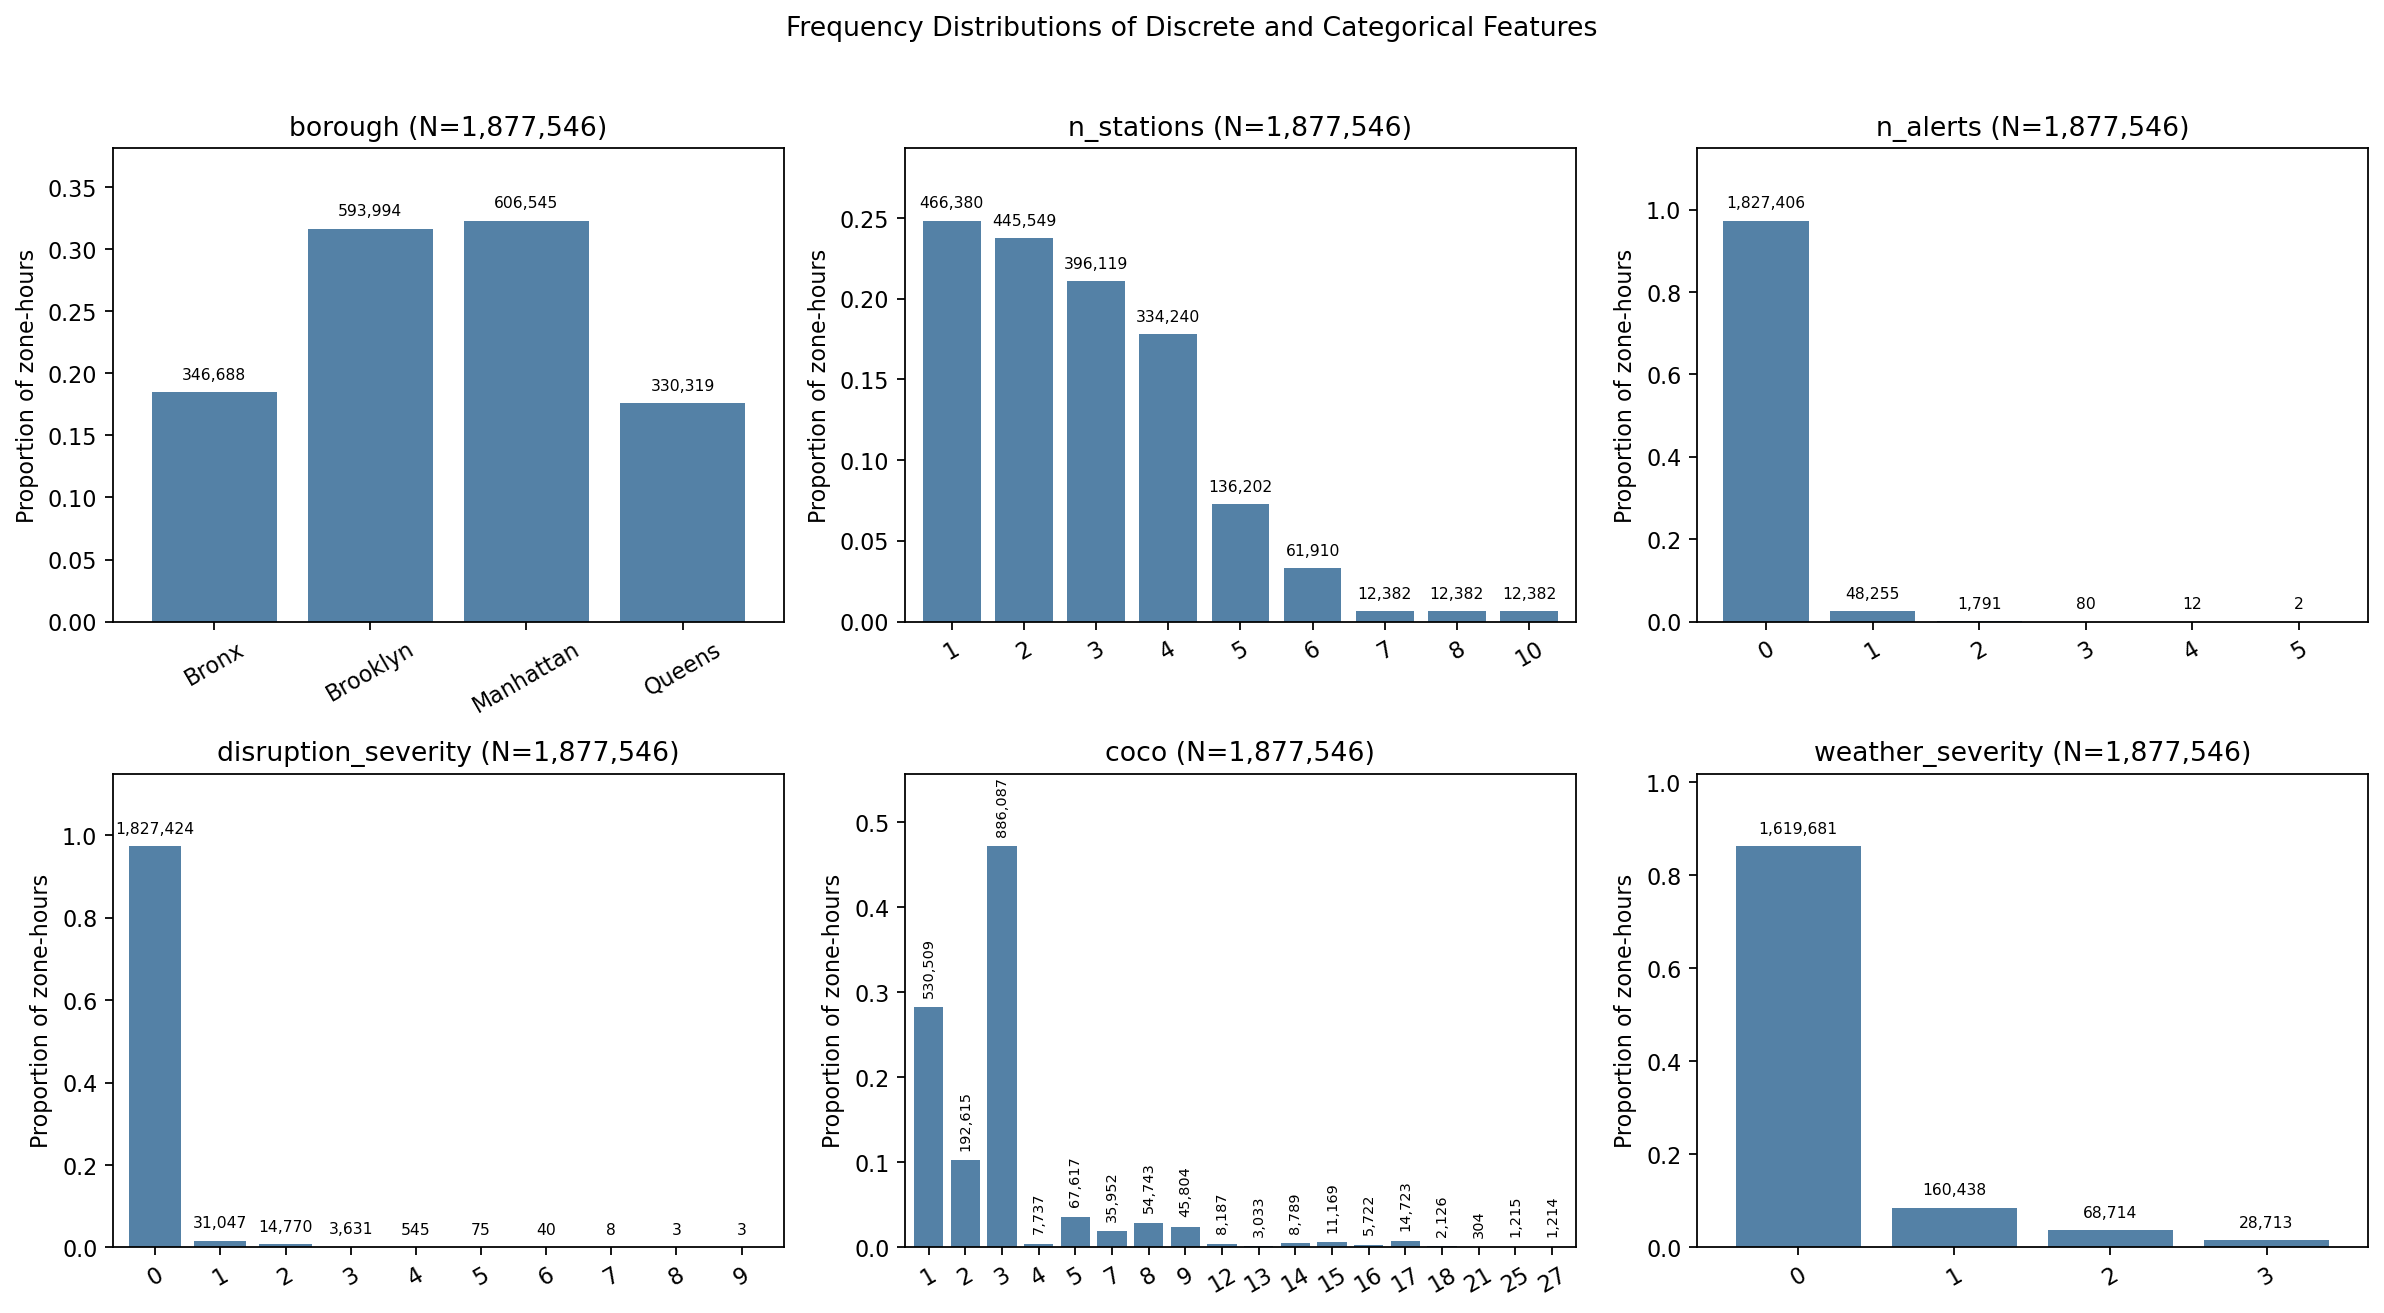

In [7]:
# Historgram plots for visualising frequency of each listed attribute
fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=160)
axes = axes.flatten()

for ax, col in zip(axes, frequency_feature_cols):
    freq_pd = (
        sdf_tlc_hourly
        .groupBy(col)
        .agg(F.count("*").alias("n_rows"))
        .withColumn("prop", F.col("n_rows") / F.lit(total_rows))
        .orderBy(col)
        .toPandas()
    )

    sns.barplot(
        data=freq_pd,
        x=col,
        y="prop",
        ax=ax,
        color="steelblue"
    )

    # Add plot padding so labels do not touch frame
    y_max = freq_pd["prop"].max()
    y_pad = y_max * 0.18 if y_max > 0 else 0.05
    ax.set_ylim(0, y_max + y_pad)

    n_bars = len(freq_pd)
    ax.set_xlim(-0.65, n_bars - 0.35)

    # Label bars with counts
    label_offset = y_max * 0.025 if y_max > 0 else 0.01

    for patch, n in zip(ax.patches, freq_pd["n_rows"]):
        height = patch.get_height()
        x = patch.get_x() + patch.get_width() / 2

        if col == "coco":
            ax.text(
                x,
                height + label_offset,
                f"{int(n):,}",
                ha="center",
                va="bottom",
                fontsize=6.5,
                rotation=90
            )
        else:
            ax.text(
                x,
                height + label_offset,
                f"{int(n):,}",
                ha="center",
                va="bottom",
                fontsize=7
            )

    ax.set_title(f"{col} (N={total_rows:,})")
    ax.set_xlabel("")
    ax.set_ylabel("Proportion of zone-hours")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Frequency Distributions of Discrete and Categorical Features", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# Categorise borough services into taxis and fhvhvs for analysis
borough_service_pd = (
    sdf_tlc_hourly
    .groupBy("borough")
    .agg(
        F.sum("n_trips_taxi").alias("taxi_trips"),
        F.sum("n_trips_fhvhv").alias("fhvhv_trips")
    )
    .orderBy("borough")
    .toPandas()
)

borough_service_long = borough_service_pd.melt(
    id_vars="borough",
    value_vars=["taxi_trips", "fhvhv_trips"],
    var_name="service_type",
    value_name="n_trips"
)

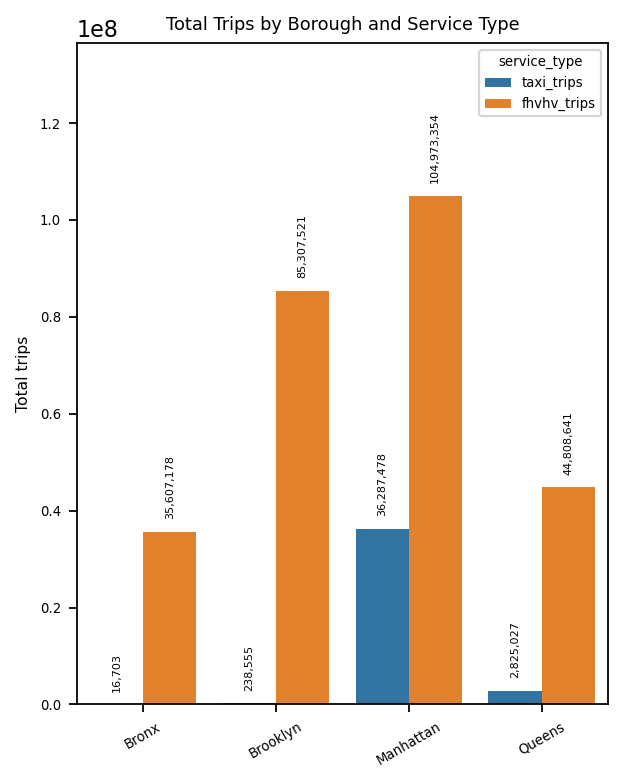

In [9]:
# Plot borough services for taxis and fhvhvs respectively for comparison
fig, ax = plt.subplots(figsize=(4, 5), dpi=160)

sns.barplot(
    data=borough_service_long,
    x="borough",
    y="n_trips",
    hue="service_type",
    ax=ax
)

# Add vertical space for labels
y_max = borough_service_long["n_trips"].max()
ax.set_ylim(0, y_max * 1.3)

for patch in ax.patches:
    height = patch.get_height()

    if height > 0:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            height + y_max * 0.025,
            f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=5,
            rotation=90
        )

ax.set_title("Total Trips by Borough and Service Type", fontsize=8)
ax.set_xlabel("", fontsize=7)
ax.set_ylabel("Total trips", fontsize=7)

ax.tick_params(axis="x", labelsize=6, rotation=30)
ax.tick_params(axis="y", labelsize=6)

ax.legend(
    title="service_type",
    title_fontsize=6,
    fontsize=6,
    loc="upper right"
)

plt.tight_layout()
plt.show()

We can see that there's a large discrepancy between number of taxi trips and fhvhv trips. In particular, although taxi trips make up a noticeable proportions of trips in Manhattan, Bronx, Brooklyn barely have any taxi trips, when compared relatively to fhvhv trips. Queens have some share, presumeably due to airport pick ups. Clearly, the combined taxis (yellow + green) are more predominantly in Manhattan, although green taxis were designed to meet outer-borough needs, as they are extremely outnumbered by fhvhv services.

### Analyse features by summary statistics and box plot
For features in `boxplot_feature_cols`, investigate their mean, stddev, 5-number summary, and plot box plot.

#### Calculate summary statistics

In [10]:
# Set required statistics
stats = ["count", "mean", "stddev", "min", "25%", "50%", "75%", "max"]
stack_expr = ", ".join([f"'{c}', `{c}`" for c in boxplot_feature_cols])

# Create table for summary statistics
summary_stats = (
    sdf_tlc_hourly
    .select(boxplot_feature_cols)
    .summary(*stats)
    .select( # round mean and stddev for readability
        "summary",
        *[
            F.when(
                F.col("summary").isin(["mean", "stddev"]),
                F.round(F.col(c).cast("double"), 3).cast("string")
            ).otherwise(F.col(c)).alias(c)
            for c in boxplot_feature_cols
        ]
    )
    .selectExpr( # transpose table to display statistics as columns
        "summary",
        f"stack({len(boxplot_feature_cols)}, {stack_expr}) as (feature, value)"
    )
    .groupBy("feature")
    .pivot("summary", stats)
    .agg(F.first("value"))
)

summary_stats.show(truncate=False)

+-------------------+-------+-------+--------+---+------+------+------+------+
|feature            |count  |mean   |stddev  |min|25%   |50%   |75%   |max   |
+-------------------+-------+-------+--------+---+------+------+------+------+
|avg_wait_time_fhvhv|1877420|296.802|89.924  |0.0|238.73|277.36|332.69|3400.0|
|n_trips_fhvhv      |1877546|144.176|122.84  |0  |59    |113   |196   |2453  |
|n_trips_taxi       |1877546|20.968 |57.521  |0  |0     |0     |5     |847   |
|ridership          |1877546|980.409|1725.183|0  |107   |403   |1136  |34341 |
+-------------------+-------+-------+--------+---+------+------+------+------+



#### Calculate IQR and outlier information

In [11]:
# Analyse IQR and outliers of each numeric feature
iqr_rows = []

for col in boxplot_feature_cols:
    q1, q3 = sdf_tlc_hourly.approxQuantile(col, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = (
        sdf_tlc_hourly
        .filter((F.col(col) < lower) | (F.col(col) > upper))
        .count()
    )

    total = sdf_tlc_hourly.select(col).dropna().count()

    iqr_rows.append((col, q1, q3, iqr, lower, upper, n_outliers, total))

# Create and format summary table for IQR and outlier information
iqr_outlier_summary = spark.createDataFrame(
    iqr_rows,
    ["feature", "q1", "q3", "iqr", "lower_bound", "upper_bound", "n_outliers", "n_non_null"]
).withColumn(
    "outlier_prop",
    F.round(F.col("n_outliers") / F.col("n_non_null"), 4)
)

iqr_outlier_summary = iqr_outlier_summary.select(
    "feature",
    F.round("q1", 2).alias("q1"),
    F.round("q3", 2).alias("q3"),
    F.round("iqr", 2).alias("iqr"),
    F.round("lower_bound", 2).alias("lower_bound"),
    F.round("upper_bound", 2).alias("upper_bound"),
    "n_outliers",
    "n_non_null",
    F.round("outlier_prop", 4).alias("outlier_prop"),
)

iqr_outlier_summary.show(truncate=False)

+-------------------+------+------+------+-----------+-----------+----------+----------+------------+
|feature            |q1    |q3    |iqr   |lower_bound|upper_bound|n_outliers|n_non_null|outlier_prop|
+-------------------+------+------+------+-----------+-----------+----------+----------+------------+
|n_trips_taxi       |0.0   |5.0   |5.0   |-7.5       |12.5       |377757    |1877546   |0.2012      |
|n_trips_fhvhv      |58.0  |194.0 |136.0 |-146.0     |398.0      |73172     |1877546   |0.039       |
|avg_wait_time_fhvhv|238.54|331.04|92.5  |99.79      |469.79     |78541     |1877420   |0.0418      |
|ridership          |104.0 |1128.0|1024.0|-1432.0    |2664.0     |163854    |1877546   |0.0873      |
+-------------------+------+------+------+-----------+-----------+----------+----------+------------+



In [12]:
# For `n_trips_taxi`, 20.12% of zone-hour entries are considered outliers, investigate by each borough 
(
    sdf_tlc_hourly
    .groupBy("borough")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg((F.col("n_trips_taxi") == 0).cast("double")), 4).alias("zero_trips_prop"),
        F.round(F.avg("n_trips_taxi"), 3).alias("avg_taxi_trips"),
        F.round(F.stddev("n_trips_taxi"), 3).alias("sd_taxi_trips"),
        F.expr("percentile_approx(n_trips_taxi, array(0.5, 0.75, 0.9, 0.99))").alias("taxi_trip_quantiles"),
        F.max("n_trips_taxi").alias("max_taxi_trips")
    )
    .orderBy("borough")
    .show(truncate=False)
)
# turns out, asides from Manhattan, it is quite common to have 0 taxi pickups in a given (PULocationID, hour), explaining the large number of outliers

+---------+------------+---------------+--------------+-------------+-------------------+--------------+
|borough  |n_zone_hours|zero_trips_prop|avg_taxi_trips|sd_taxi_trips|taxi_trip_quantiles|max_taxi_trips|
+---------+------------+---------------+--------------+-------------+-------------------+--------------+
|Bronx    |346688      |0.9592         |0.048         |0.3          |[0, 0, 0, 1]       |21            |
|Brooklyn |593994      |0.8309         |0.402         |1.316        |[0, 0, 1, 7]       |44            |
|Manhattan|606545      |0.1177         |59.827        |82.588       |[24, 87, 167, 384] |847           |
|Queens   |330319      |0.5746         |8.552         |46.171       |[0, 2, 4, 301]     |680           |
+---------+------------+---------------+--------------+-------------+-------------------+--------------+



In [13]:
# For `n_trips_fhvhv` in comparison, only 3.9% of zone-hour entries are considered outliers, investigate by each borough for comparison
(
    sdf_tlc_hourly
    .groupBy("borough")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg((F.col("n_trips_fhvhv") == 0).cast("double")), 4).alias("zero_trips_prop"),
        F.round(F.avg("n_trips_fhvhv"), 3).alias("avg_fhvhv_trips"),
        F.round(F.stddev("n_trips_fhvhv"), 3).alias("sd_fhvhv_trips"),
        F.expr("percentile_approx(n_trips_fhvhv, array(0.5, 0.75, 0.9, 0.99))").alias("fhvhv_trip_quantiles"),
        F.max("n_trips_fhvhv").alias("max_fhvhv_trips")
    )
    .orderBy("borough")
    .show(truncate=False)
)
# turns out, asides from Manhattan, it is quite common to have 0 taxi pickups in a given (PULocationID, hour), explaining the large number of outliers

+---------+------------+---------------+---------------+--------------+--------------------+---------------+
|borough  |n_zone_hours|zero_trips_prop|avg_fhvhv_trips|sd_fhvhv_trips|fhvhv_trip_quantiles|max_fhvhv_trips|
+---------+------------+---------------+---------------+--------------+--------------------+---------------+
|Bronx    |346688      |0.0            |102.707        |59.054        |[95, 139, 182, 267] |675            |
|Brooklyn |593994      |0.0            |143.617        |123.827       |[110, 196, 299, 595]|1870           |
|Manhattan|606545      |1.0E-4         |173.068        |138.818       |[149, 238, 338, 652]|2453           |
|Queens   |330319      |2.0E-4         |135.653        |125.463       |[99, 195, 282, 619] |1515           |
+---------+------------+---------------+---------------+--------------+--------------------+---------------+



#### Boxplots for relevant numeric features
Normal scale, then log scale for comparison. 

In [14]:
# Prepare pandas df for box plotting
numeric_pd = (
    sdf_tlc_hourly
    .select(boxplot_feature_cols)
    .dropna()
    .toPandas()
)
sdf_tlc_hourly_count = sdf_tlc_hourly.count()

print(f"sdf_tlc_hourly rows:          {sdf_tlc_hourly_count}")
print(f"sdf_tlc_hourly.dropna() rows: {len(numeric_pd)}")
print(f"rows dropped:                 {sdf_tlc_hourly_count - len(numeric_pd)} ")

sdf_tlc_hourly rows:          1877546
sdf_tlc_hourly.dropna() rows: 1877420
rows dropped:                 126 


In [15]:
# 126 rows dropped, investigate what kind of rows they are to safety check 
rows_with_missing_boxplot_features = (
    sdf_tlc_hourly
    .select("hour", "PULocationID", "borough", "taxi_zone", *boxplot_feature_cols)
    .filter(
        F.col("n_trips_taxi").isNull()
        | F.col("n_trips_fhvhv").isNull()
        | F.col("avg_wait_time_fhvhv").isNull()
        | F.col("ridership").isNull()
    )
)

rows_with_missing_boxplot_features.show(10, truncate=False)

+-------------------+------------+---------+----------------------------+------------+-------------+-------------------+---------+
|hour               |PULocationID|borough  |taxi_zone                   |n_trips_taxi|n_trips_fhvhv|avg_wait_time_fhvhv|ridership|
+-------------------+------------+---------+----------------------------+------------+-------------+-------------------+---------+
|2026-03-30 02:00:00|93          |Queens   |Flushing Meadows-Corona Park|1           |0            |NULL               |58       |
|2026-04-11 03:00:00|178         |Brooklyn |Ocean Parkway South         |1           |0            |NULL               |7        |
|2026-04-12 03:00:00|43          |Manhattan|Central Park                |2           |0            |NULL               |24       |
|2026-04-13 02:00:00|43          |Manhattan|Central Park                |1           |0            |NULL               |18       |
|2026-04-19 09:00:00|30          |Queens   |Broad Channel               |1         

In [16]:
# looks like a common reason is NULL in `avg_wait_time_fhvhv`, investigate if all of them are this way
wait_time_null_count = sdf_tlc_hourly.select("hour", "PULocationID", *boxplot_feature_cols).filter(F.col("avg_wait_time_fhvhv").isNull()).count()
print(f"No. rows with NULL in avg_wait_time_fhvhv:        {wait_time_null_count}")

n_trips_ridership_null_count = (sdf_tlc_hourly.
                                select("hour", "PULocationID", *boxplot_feature_cols)
                                .filter(F.col("n_trips_taxi").isNull() | F.col("n_trips_fhvhv").isNull() | F.col("ridership").isNull())
                                .count())
print(f"No. rows with NULL in any other selected columns: {n_trips_ridership_null_count}")

# all 126 rows are due to `avg_wait_time_fhvhv` NULL, investigate if they are anomaly
(
    sdf_tlc_hourly
    .filter(F.col("avg_wait_time_fhvhv").isNull())
    .groupBy("n_trips_fhvhv")
    .agg(F.count("*").alias("n_rows"))
    .orderBy("n_trips_fhvhv")
    .show(truncate=False)
)
# no anomaly, all NULL values arise due to n_trips_fhvhv=0, which is very rare but exists (126/1877546=0.0067% of all zone-hour entries)

No. rows with NULL in avg_wait_time_fhvhv:        126
No. rows with NULL in any other selected columns: 0
+-------------+------+
|n_trips_fhvhv|n_rows|
+-------------+------+
|0            |126   |
+-------------+------+



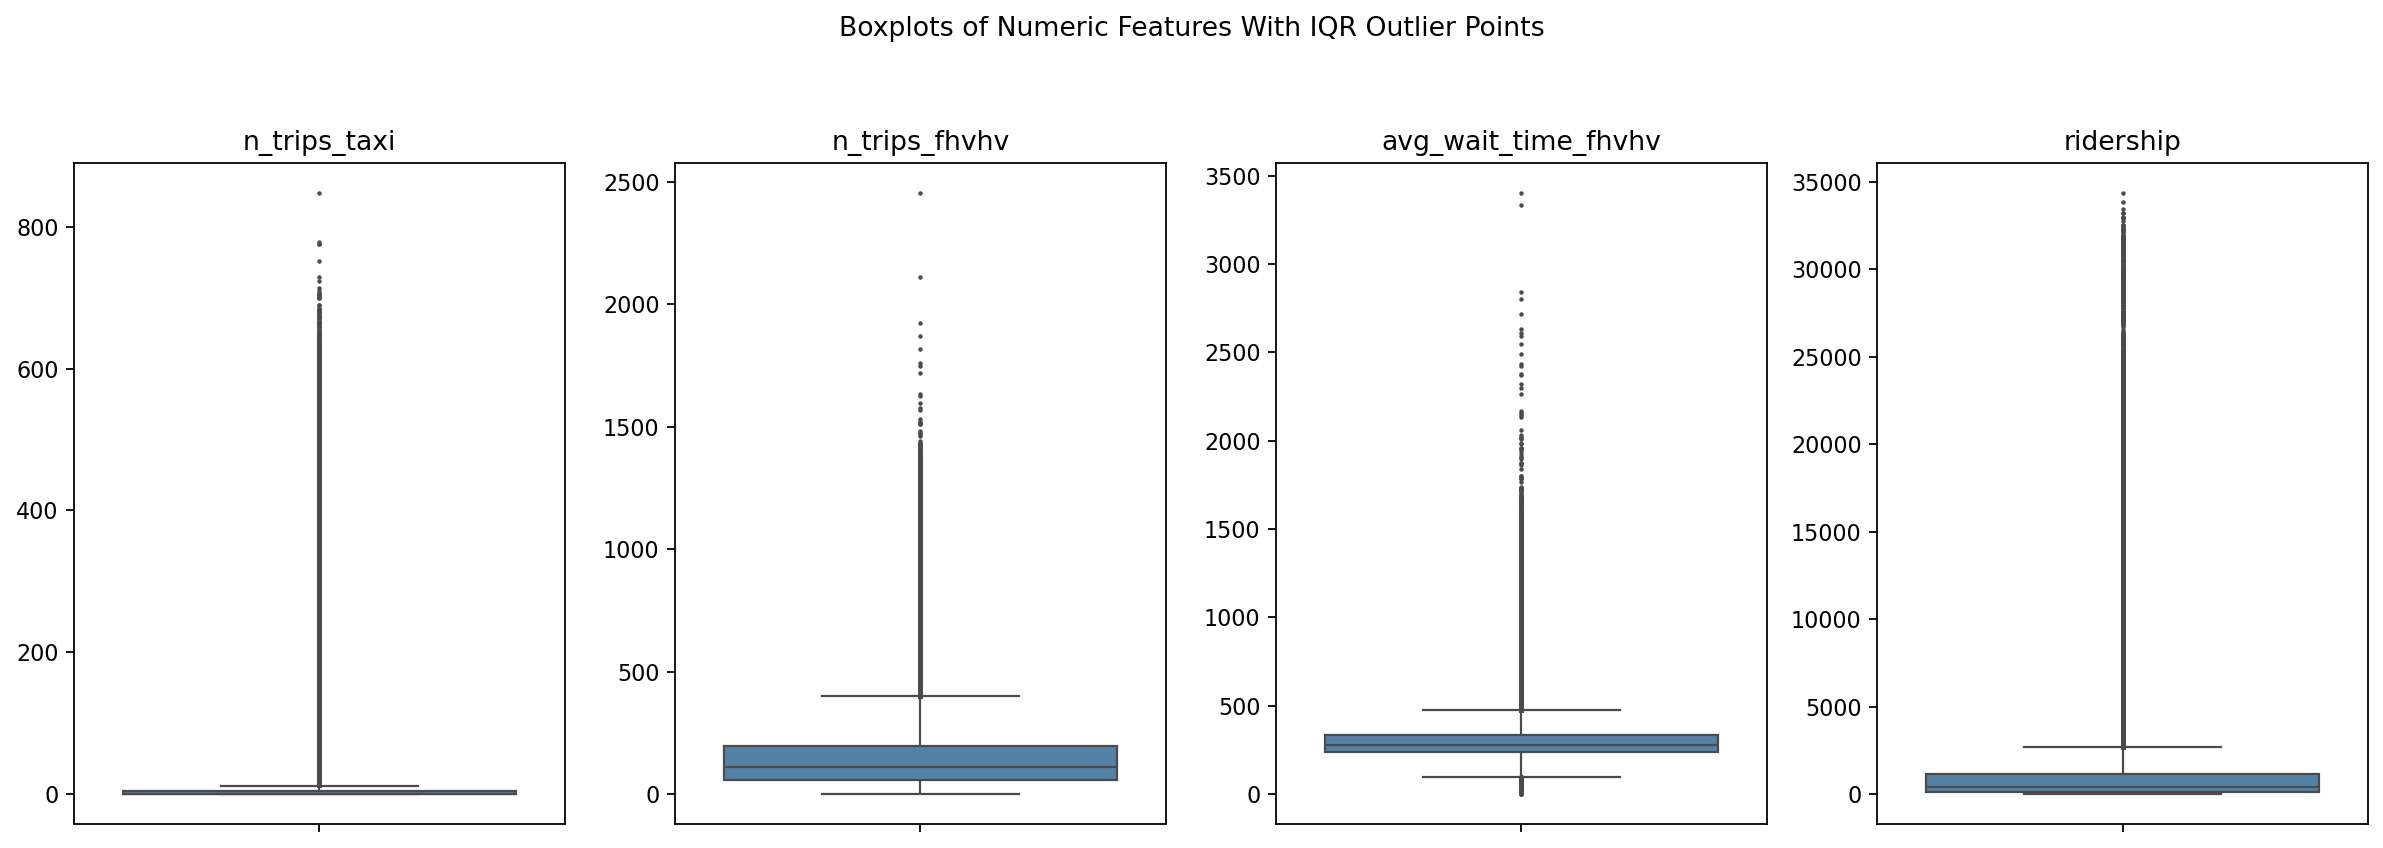

In [17]:
# Plot the box plots! with outlier points
fig, axes = plt.subplots(1, 4, figsize=(15, 5), dpi=160)

for ax, col in zip(axes.flatten(), boxplot_feature_cols):
    sns.boxplot(
        y=numeric_pd[col],
        ax=ax,
        color="steelblue",
        showfliers=True,
        fliersize=1
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Boxplots of Numeric Features With IQR Outlier Points", y=1.05)
plt.tight_layout()
plt.show()
# The box plots are quite hard to read as the data is highly skewed + many outliers 

The raw scale plots are quite difficult to read, as the data is quite skewed. We use a log(1+x) transformation to handle zero counts in the attributes. 
$$\texttt{np.log1p}(x) = \log(1+x)$$

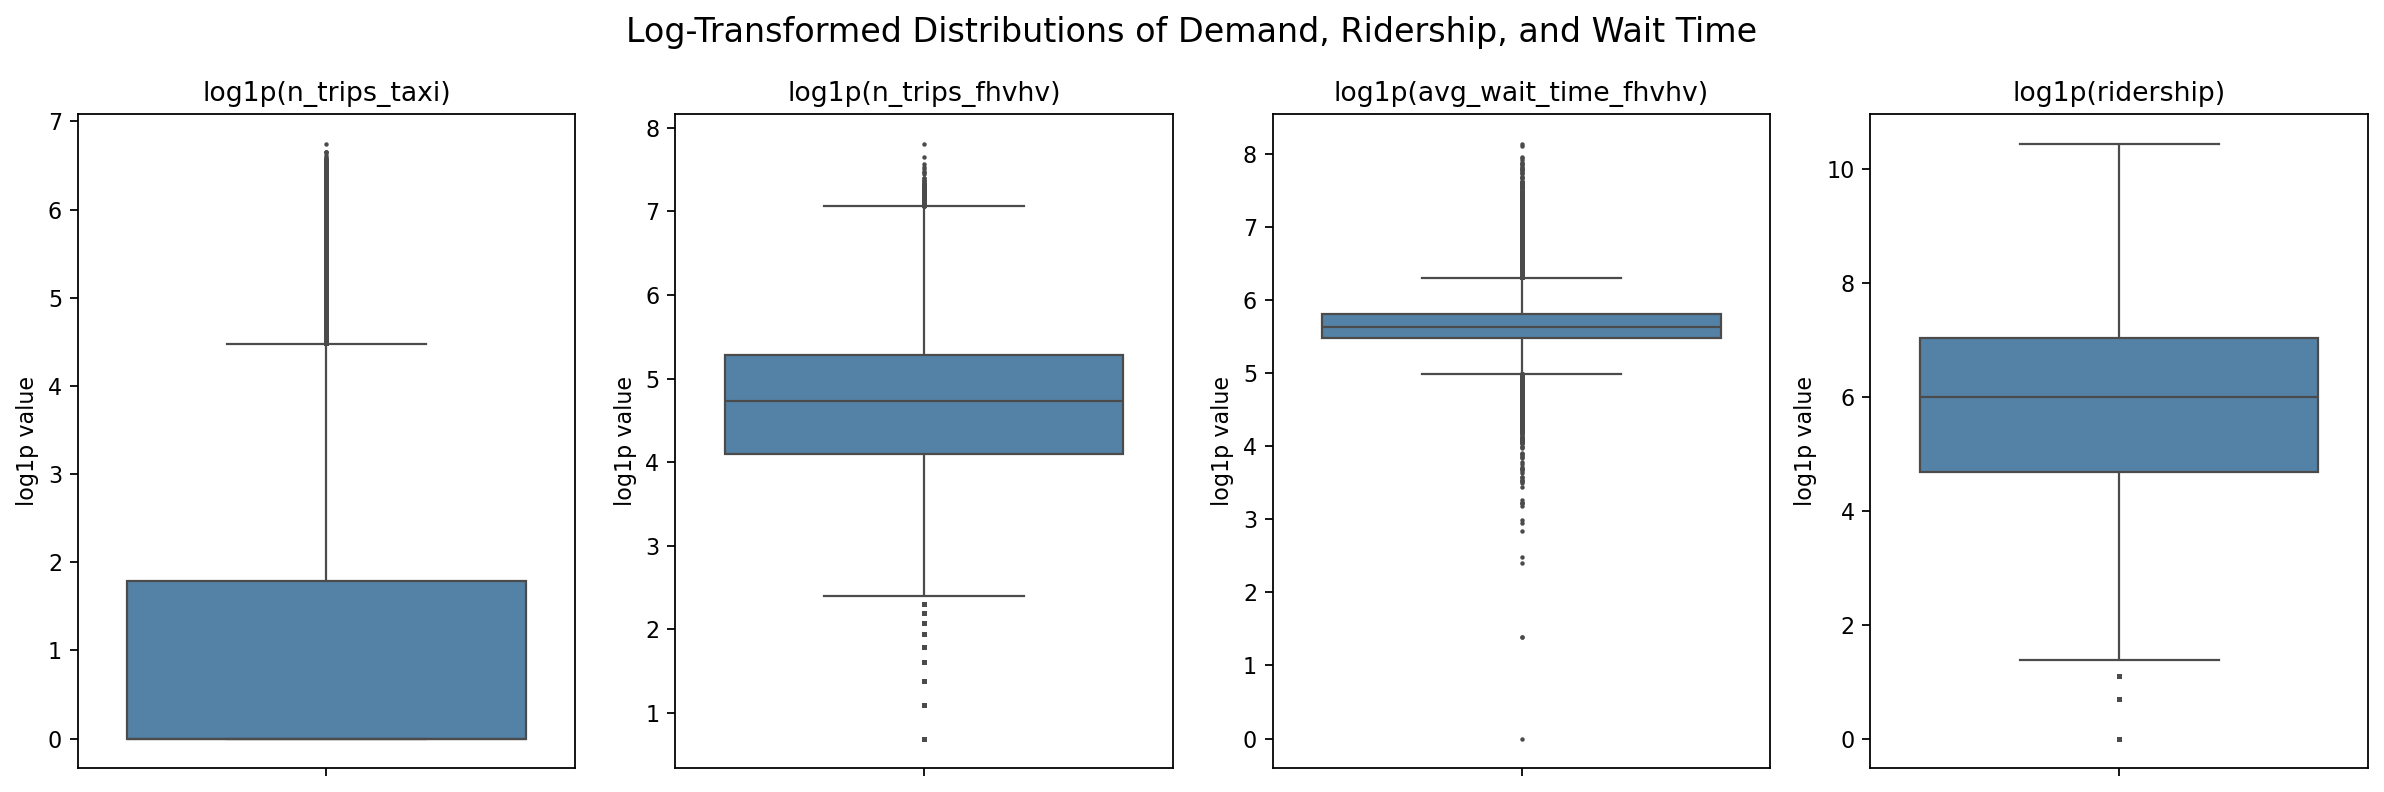

In [18]:
# Plot the box plots on log scale for better visualisation! with outlier points
log_plot_pd = (
    sdf_tlc_hourly
    .select(boxplot_feature_cols)
    .dropna()
    .toPandas()
)

# Add log(1+x) column for plotting
for col in boxplot_feature_cols:
    log_plot_pd[f"log1p_{col}"] = np.log1p(log_plot_pd[col])

log_boxplot_cols = [f"log1p_{col}" for col in boxplot_feature_cols]

fig, axes = plt.subplots(1, 4, figsize=(15, 5), dpi=160)
for ax, col in zip(axes, log_boxplot_cols):
    sns.boxplot(
        y=log_plot_pd[col],
        ax=ax,
        color="steelblue",
        showfliers=True,
        fliersize=1
    )
    ax.set_title(col.replace("log1p_", "log1p(") + ")")
    ax.set_ylabel("log1p value")

plt.suptitle("Log-Transformed Distributions of Demand, Ridership, and Wait Time", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

### Kernel Density Estimation for numeric features distribution
We show the original vs. log-transformed distributions with KDE

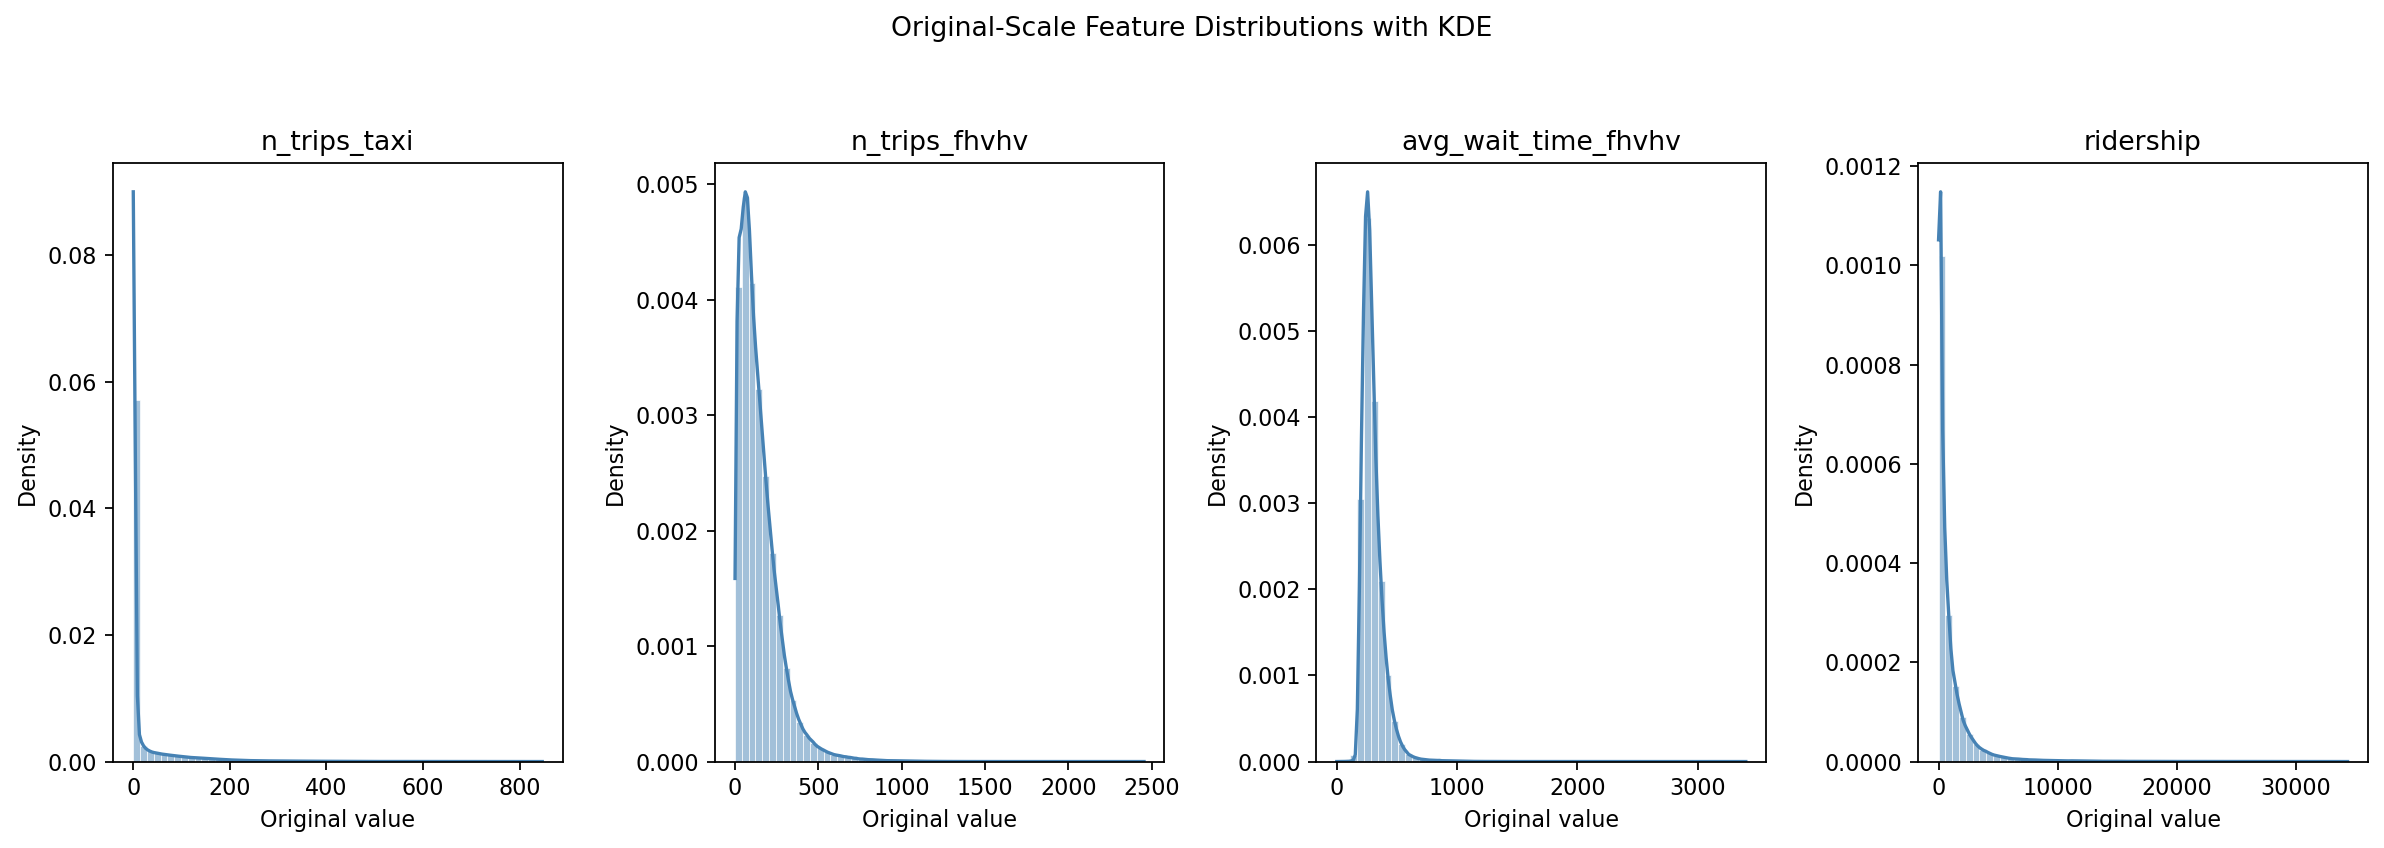

In [19]:
original_plot_pd = (
    sdf_tlc_hourly
    .select(boxplot_feature_cols)
    .dropna()
    .toPandas()
)

fig, axes = plt.subplots(1, len(boxplot_feature_cols), figsize=(15, 5), dpi=160)

for ax, col in zip(axes, boxplot_feature_cols):
    sns.histplot(
        data=original_plot_pd,
        x=col,
        bins=60,
        stat="density",
        kde=True,
        ax=ax,
        color="steelblue",
        edgecolor="white",
        linewidth=0.3
    )

    ax.set_title(col)
    ax.set_xlabel("Original value")
    ax.set_ylabel("Density")

plt.suptitle("Original-Scale Feature Distributions with KDE", y=1.05)
plt.tight_layout()
plt.show()

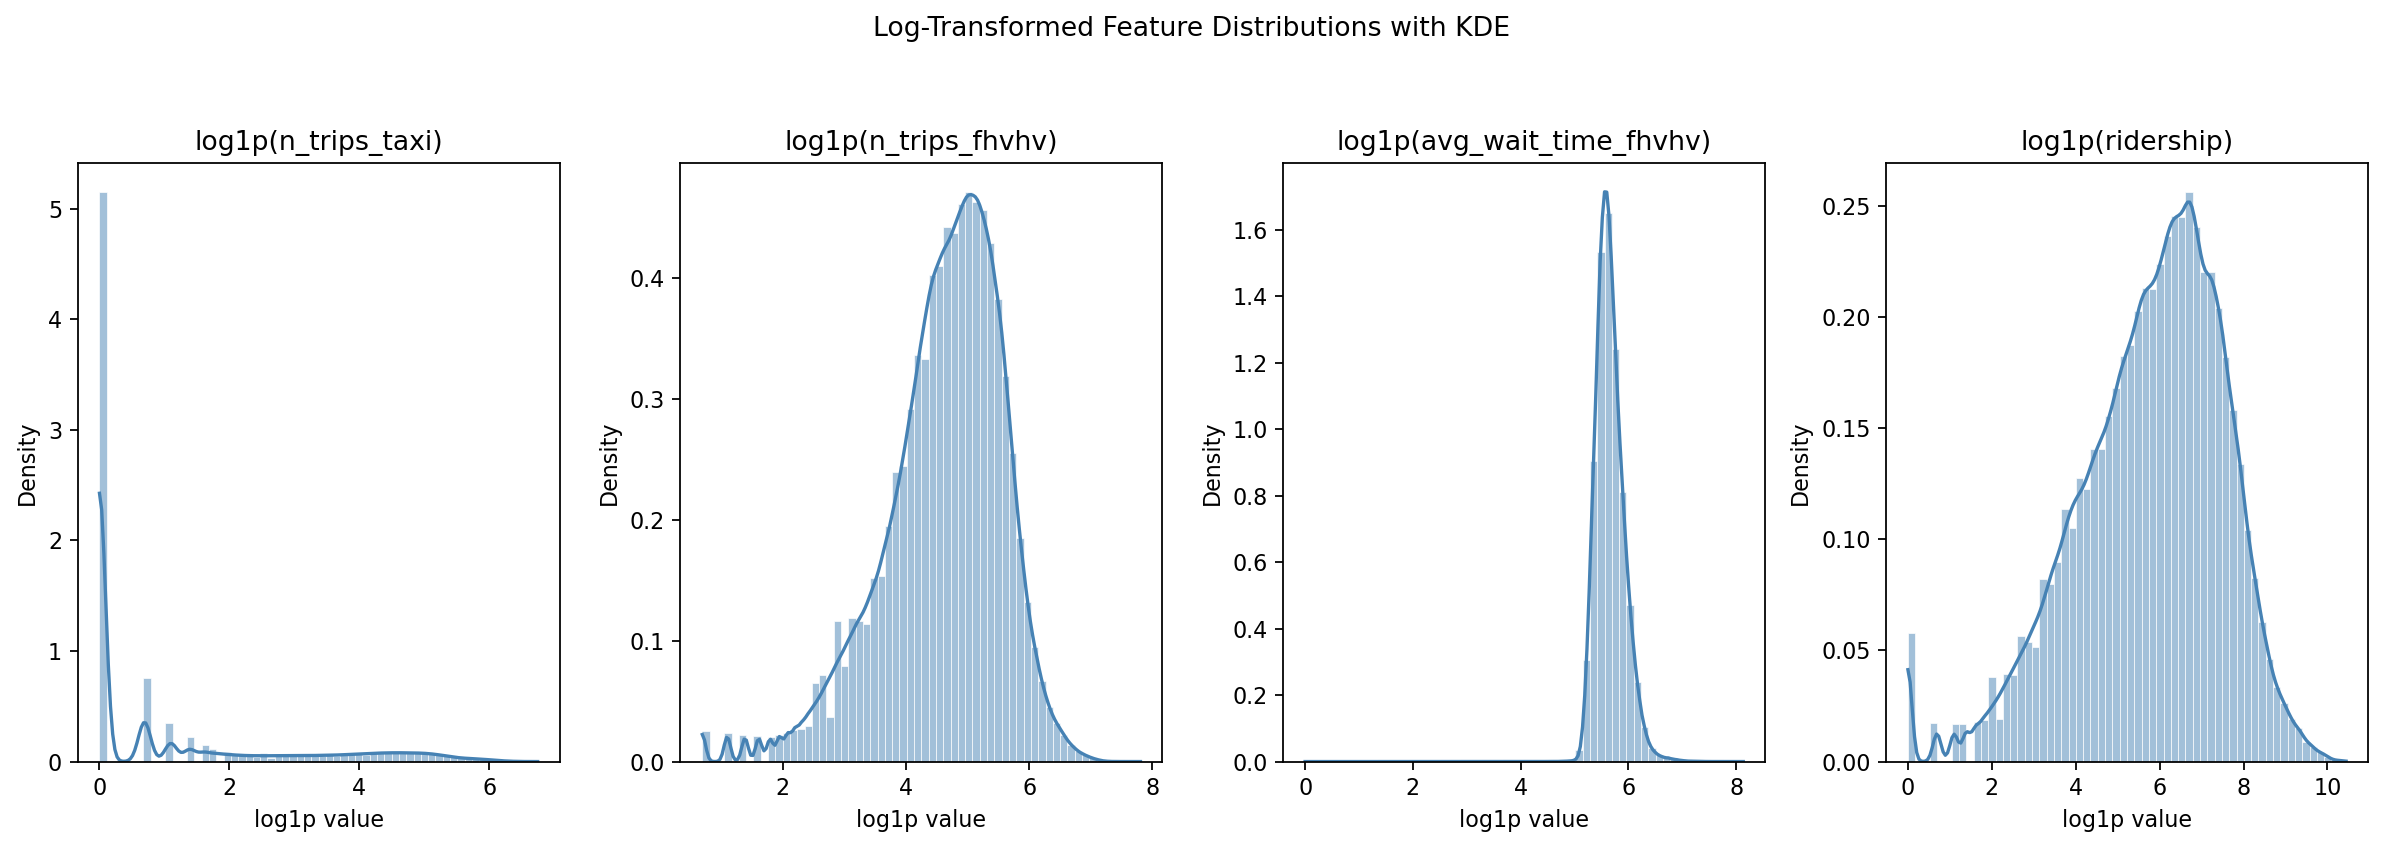

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 5), dpi=160)

for ax, col in zip(axes, log_boxplot_cols):
    sns.histplot(
        data=log_plot_pd,
        x=col,
        bins=60,
        stat="density",
        kde=True,
        ax=ax,
        color="steelblue",
        edgecolor="white",
        linewidth=0.3
    )

    ax.set_title(col.replace("log1p_", "log1p(") + ")")
    ax.set_xlabel("log1p value")
    ax.set_ylabel("Density")

plt.suptitle("Log-Transformed Feature Distributions with KDE", y=1.05)
plt.tight_layout()
plt.show()

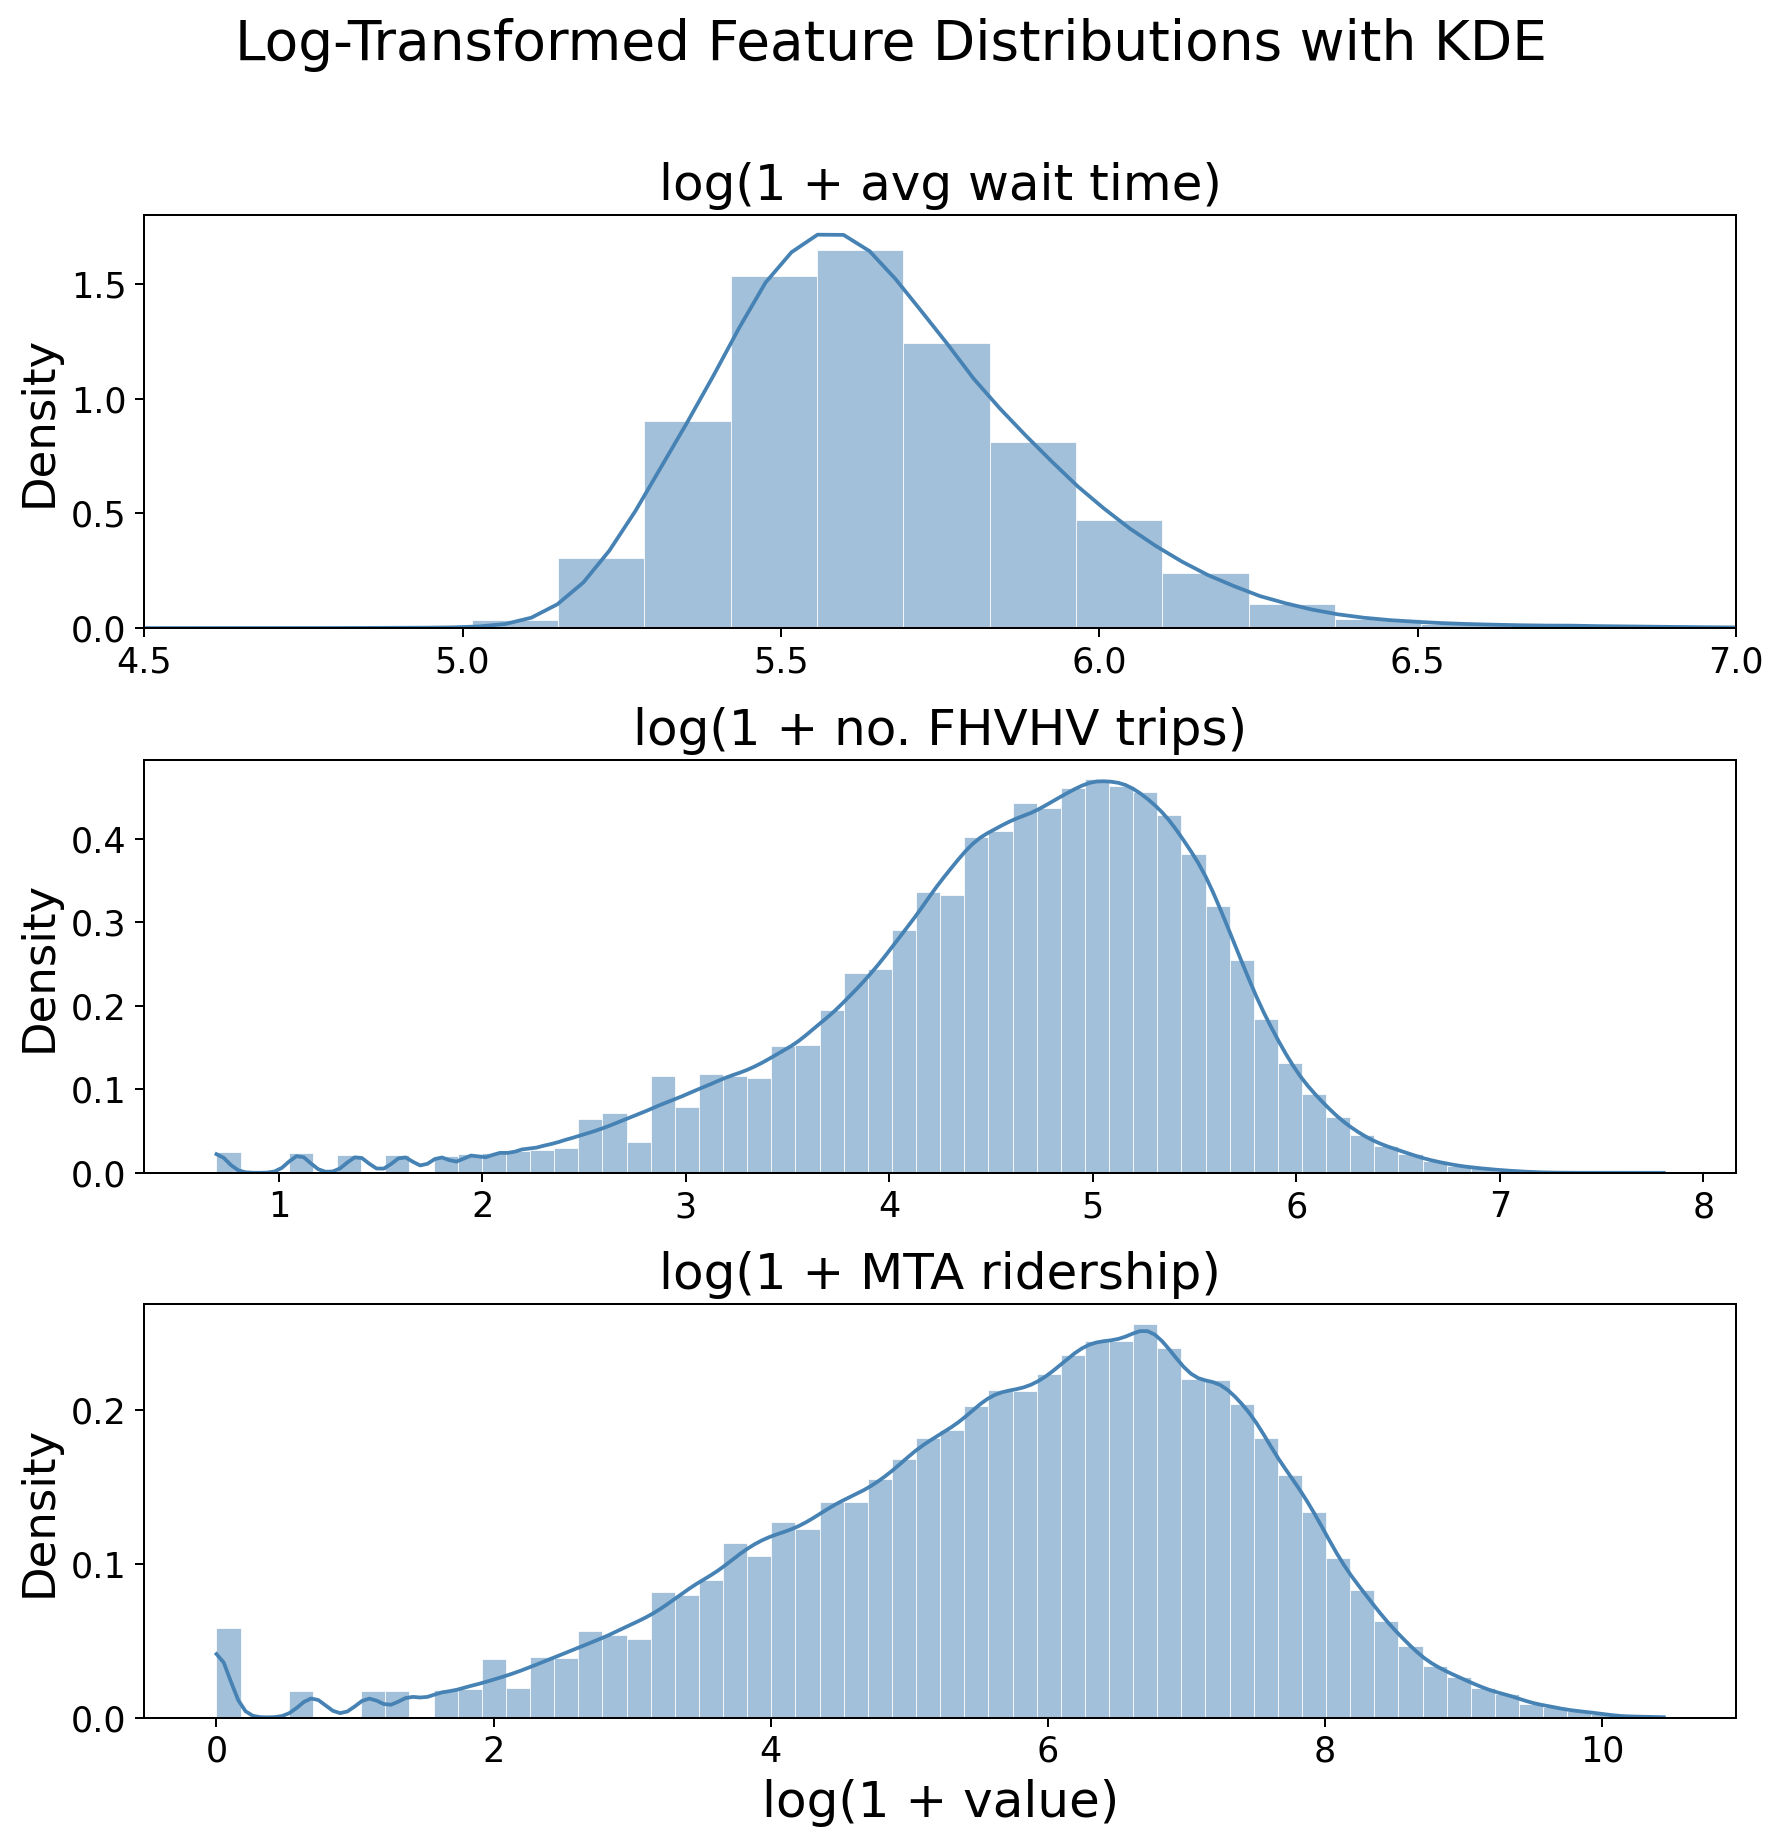

In [ ]:
# Bigger more readable plot for report 
fig, axes = plt.subplots(3, 1, figsize=(10, 10), dpi=180)

log_kde_cols = [
    "log1p_avg_wait_time_fhvhv",
    "log1p_n_trips_fhvhv",
    "log1p_ridership",
]

plot_titles = {
    "log1p_avg_wait_time_fhvhv": "log(1 + avg wait time)",
    "log1p_n_trips_fhvhv": "log(1 + no. FHVHV trips)",
    "log1p_ridership": "log(1 + MTA ridership)",
}

for ax, col in zip(axes, log_kde_cols):
    sns.histplot(
        data=log_plot_pd,
        x=col,
        bins=60,
        stat="density",
        kde=True,
        ax=ax,
        color="steelblue",
        edgecolor="white",
        linewidth=0.3
    )

    if col == "log1p_avg_wait_time_fhvhv":
        ax.set_xlim(4.5, 7.0)

    ax.set_title(plot_titles[col], fontsize=24)
    ax.set_xlabel("")
    ax.set_ylabel("Density", fontsize=20)
    ax.tick_params(axis="both", labelsize=16)

axes[-1].set_xlabel("log(1 + value)", fontsize=24)

plt.suptitle("Log-Transformed Feature Distributions with KDE", fontsize=22, y=1.02)
plt.tight_layout()
plt.show()

### Distribution analysis: findings and interpretation
- `n_trips_taxi` behaves very differently in high-demand boroughs (Manhattan, Queens) vs. low-demand boroughs (Brooklyn, Bronx)
- `n_trips_fhvhv` and `ridership` seem to be suitable for a log-transformation in modelling
- `avg_wait_time_fhvhv` log-transformed is unimodal with extreme values, may not be suitable for log-transformation in modelling 

## Interaction analysis
Looking at interaction between features for TLC trips, wait time, and MTA ridership. 

Visualised by borough and by weekday/weekend. This is an example of looking at interaction between the attributes.

+-----------+------------+--------------------+---------------------+--------------------+--------------------+
|alert_level|n_zone_hours|avg_taxi_trip_change|avg_fhvhv_trip_change|avg_wait_time_change|avg_ridership_change|
+-----------+------------+--------------------+---------------------+--------------------+--------------------+
|0_no_alert |1827424     |-1.0E-4             |-1.0E-4              |1.0E-4              |0.0018              |
|1_low      |31047       |0.5004              |1.7866               |1.287               |13.1062             |
|2_medium   |14770       |0.6048              |2.4816               |2.907               |27.3148             |
|3_high     |4305        |0.4792              |0.4781               |11.824              |-8.7161             |
+-----------+------------+--------------------+---------------------+--------------------+--------------------+



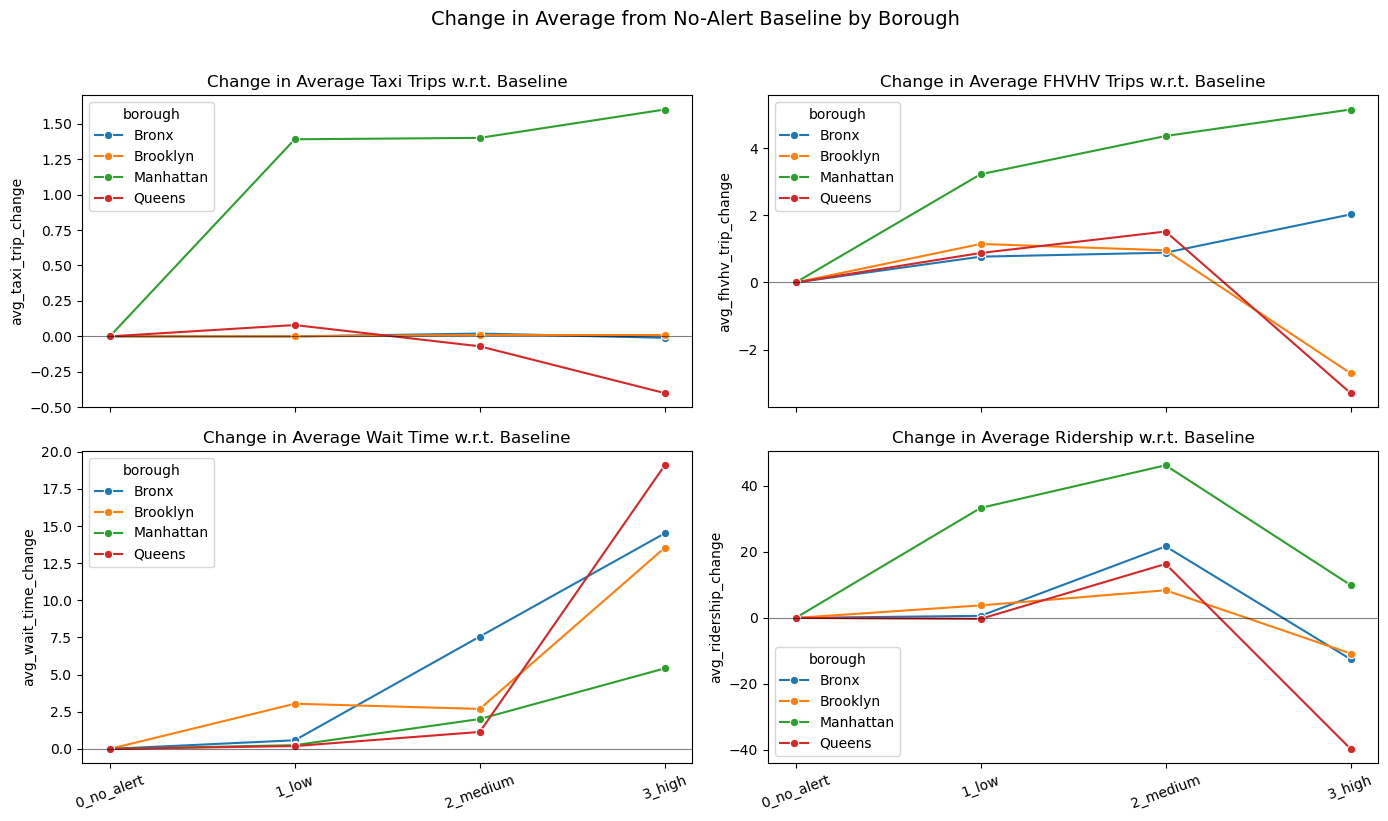

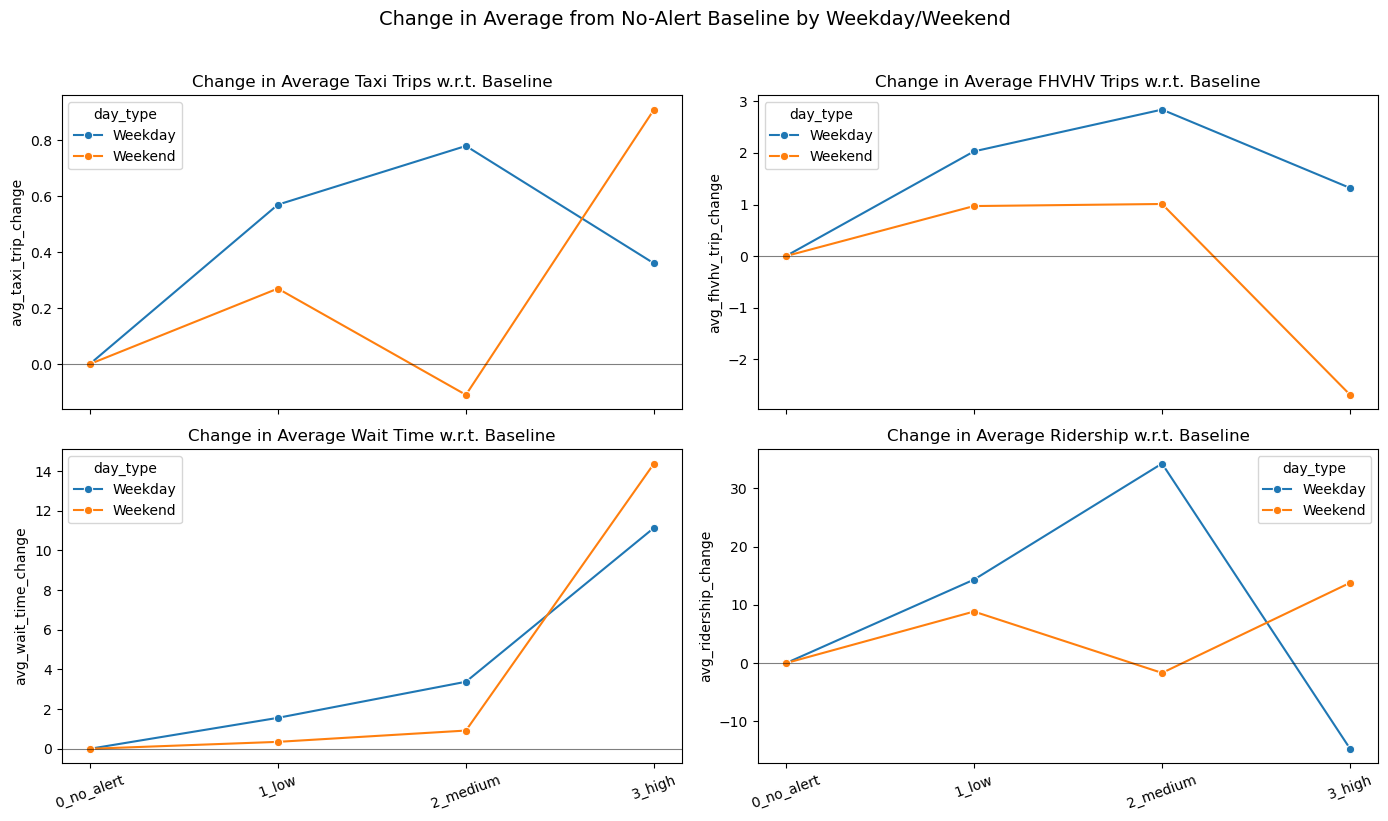

In [21]:
# -------------------------------------------------------------------
# 1. Build analysis table
# -------------------------------------------------------------------

analysis_df = (
    sdf_tlc_hourly
    .withColumn("hour_of_day", F.hour("hour"))
    .withColumn(
        "day_type",
        F.when(F.dayofweek("hour").isin([1, 7]), "Weekend")
         .otherwise("Weekday")
    )
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
)

# -------------------------------------------------------------------
# 2. Build no-alert baseline
# Baseline is calculated separately for:
# zone + hour of day + weekday/weekend type
# -------------------------------------------------------------------

baseline_df = (
    analysis_df
    .filter(F.col("has_alert") == 0)
    .groupBy("PULocationID", "hour_of_day", "day_type")
    .agg(
        F.avg("n_trips_taxi").alias("baseline_n_trips_taxi"),
        F.avg("n_trips_fhvhv").alias("baseline_n_trips_fhvhv"),
        F.avg("avg_wait_time_fhvhv").alias("baseline_avg_wait_time_fhvhv"),
        F.avg("ridership").alias("baseline_ridership"),
    )
)

# -------------------------------------------------------------------
# 3. Compare every zone-hour against its no-alert baseline
# -------------------------------------------------------------------

alert_effect_df = (
    analysis_df
    .join(
        baseline_df,
        on=["PULocationID", "hour_of_day", "day_type"],
        how="left"
    )

    # Absolute change: observed value minus no-alert baseline
    .withColumn("taxi_trip_change", F.col("n_trips_taxi") - F.col("baseline_n_trips_taxi"))
    .withColumn("fhvhv_trip_change", F.col("n_trips_fhvhv") - F.col("baseline_n_trips_fhvhv"))
    .withColumn("wait_time_change", F.col("avg_wait_time_fhvhv") - F.col("baseline_avg_wait_time_fhvhv"))
    .withColumn("ridership_change", F.col("ridership") - F.col("baseline_ridership"))

    # Ratio: observed value divided by no-alert baseline
    .withColumn("taxi_trip_ratio",
        F.when(F.col("baseline_n_trips_taxi") > 0, F.col("n_trips_taxi") / F.col("baseline_n_trips_taxi"))
    )
    .withColumn("fhvhv_trip_ratio",
        F.when(F.col("baseline_n_trips_fhvhv") > 0, F.col("n_trips_fhvhv") / F.col("baseline_n_trips_fhvhv"))
    )
    .withColumn("wait_time_ratio",
        F.when(F.col("baseline_avg_wait_time_fhvhv") > 0, F.col("avg_wait_time_fhvhv") / F.col("baseline_avg_wait_time_fhvhv"))
    )
    .withColumn("ridership_ratio",
        F.when(F.col("baseline_ridership") > 0, F.col("ridership") / F.col("baseline_ridership"))
    )

    # Alert categories
    .withColumn("alert_level",
        F.when(F.col("disruption_severity") == 0, "0_no_alert")
         .when(F.col("disruption_severity") == 1, "1_low")
         .when(F.col("disruption_severity") == 2, "2_medium")
         .otherwise("3_high")
    )

    # Average severity per distinct alert
    .withColumn("avg_severity_per_alert",
        F.when(F.col("n_alerts") > 0, F.col("disruption_severity") / F.col("n_alerts"))
         .otherwise(0)
    )
)
alert_effect_df.write.mode("overwrite").parquet(f"{analysis_dir}/alert_effect_from_baseline")

# -------------------------------------------------------------------
# 4. Sanity check: no-alert average changes should be close to 0
# -------------------------------------------------------------------

sanity_check = (
    alert_effect_df
    .groupBy("alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("taxi_trip_change"), 4).alias("avg_taxi_trip_change"),
        F.round(F.avg("fhvhv_trip_change"), 4).alias("avg_fhvhv_trip_change"),
        F.round(F.avg("wait_time_change"), 4).alias("avg_wait_time_change"),
        F.round(F.avg("ridership_change"), 4).alias("avg_ridership_change"),
    )
    .orderBy("alert_level")
)

sanity_check.show(truncate=False)

# -------------------------------------------------------------------
# 5. By-borough summary
# -------------------------------------------------------------------

borough_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 2).alias("avg_taxi_trips"),
        F.round(F.avg("n_trips_fhvhv"), 2).alias("avg_fhvhv_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 2).alias("baseline_taxi_trips"),
        F.round(F.avg("baseline_n_trips_fhvhv"), 2).alias("baseline_fhvhv_trips"),
        F.round(F.avg("taxi_trip_change"), 2).alias("avg_taxi_trip_change"),
        F.round(F.avg("fhvhv_trip_change"), 2).alias("avg_fhvhv_trip_change"),
        F.round(F.avg("wait_time_change"), 2).alias("avg_wait_time_change"),
        F.round(F.avg("ridership_change"), 2).alias("avg_ridership_change"),
    )
    .orderBy("borough", "alert_level")
)

borough_summary_pd = borough_summary.toPandas()

# -------------------------------------------------------------------
# 6. Weekday/weekend summary
# -------------------------------------------------------------------

day_type_summary = (
    alert_effect_df
    .groupBy("day_type", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 2).alias("avg_taxi_trips"),
        F.round(F.avg("n_trips_fhvhv"), 2).alias("avg_fhvhv_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 2).alias("baseline_taxi_trips"),
        F.round(F.avg("baseline_n_trips_fhvhv"), 2).alias("baseline_fhvhv_trips"),
        F.round(F.avg("taxi_trip_change"), 2).alias("avg_taxi_trip_change"),
        F.round(F.avg("fhvhv_trip_change"), 2).alias("avg_fhvhv_trip_change"),
        F.round(F.avg("wait_time_change"), 2).alias("avg_wait_time_change"),
        F.round(F.avg("ridership_change"), 2).alias("avg_ridership_change"),
    )
    .orderBy("day_type", "alert_level")
)

day_type_summary_pd = day_type_summary.toPandas()

# -------------------------------------------------------------------
# 7. Ensure alert levels are plotted in correct order
# -------------------------------------------------------------------

alert_order = ["0_no_alert", "1_low", "2_medium", "3_high"]

for pdf in [borough_summary_pd, day_type_summary_pd]:
    pdf["alert_level"] = pd.Categorical(
        pdf["alert_level"],
        categories=alert_order,
        ordered=True
    )
    pdf.sort_values("alert_level", inplace=True)

# Summary for CI ribbon plots: borough x alert level
ci_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("fhvhv_trip_change").alias("n_fhvhv"),
        F.avg("fhvhv_trip_change").alias("avg_fhvhv_trip_change"),
        F.stddev("fhvhv_trip_change").alias("sd_fhvhv_trip_change"),

        F.count("wait_time_change").alias("n_wait"),
        F.avg("wait_time_change").alias("avg_wait_time_change"),
        F.stddev("wait_time_change").alias("sd_wait_time_change"),
    )
    .withColumn("ci95_fhvhv_trip_change", 1.96 * F.col("sd_fhvhv_trip_change") / F.sqrt("n_fhvhv"))
    .withColumn("ci95_wait_time_change", 1.96 * F.col("sd_wait_time_change") / F.sqrt("n_wait"))
)

ci_pd = ci_summary.toPandas()

ci_pd["alert_level"] = pd.Categorical(
    ci_pd["alert_level"],
    categories=alert_order,
    ordered=True
)

ci_pd = ci_pd.sort_values(["borough", "alert_level"])


# -------------------------------------------------------------------
# 8. Plot helper
# -------------------------------------------------------------------

def plot_alert_changes(summary_pd, hue_col, title):
    metrics = {
        "avg_taxi_trip_change": "Change in Average Taxi Trips w.r.t. Baseline",
        "avg_fhvhv_trip_change": "Change in Average FHVHV Trips w.r.t. Baseline",
        "avg_wait_time_change": "Change in Average Wait Time w.r.t. Baseline",
        "avg_ridership_change": "Change in Average Ridership w.r.t. Baseline",
    }

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

    for ax, (metric, subtitle) in zip(axes.flatten(), metrics.items()):
        sns.lineplot(
            data=summary_pd,
            x="alert_level",
            y=metric,
            hue=hue_col,
            marker="o",
            ax=ax
        )
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
        ax.set_title(subtitle)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=20)

    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# -------------------------------------------------------------------
# 9. Plots
# -------------------------------------------------------------------
    
plot_alert_changes(
    borough_summary_pd,
    hue_col="borough",
    title="Change in Average from No-Alert Baseline by Borough"
)

plot_alert_changes(
    day_type_summary_pd,
    hue_col="day_type",
    title="Change in Average from No-Alert Baseline by Weekday/Weekend"
)

In [22]:
# Count zone-hours by exact disruption severity score
(
    alert_effect_df
    .groupBy("disruption_severity")
    .agg(F.count("*").alias("n_zone_hours"))
    .orderBy("disruption_severity")
    .show(truncate=False)
)

+-------------------+------------+
|disruption_severity|n_zone_hours|
+-------------------+------------+
|0                  |1827424     |
|1                  |31047       |
|2                  |14770       |
|3                  |3631        |
|4                  |545         |
|5                  |75          |
|6                  |40          |
|7                  |8           |
|8                  |3           |
|9                  |3           |
+-------------------+------------+



In [23]:
# Count zone-hours by alert level bucket
(
    alert_effect_df
    .groupBy("alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.min("disruption_severity").alias("min_severity"),
        F.max("disruption_severity").alias("max_severity"),
        F.round(F.avg("disruption_severity"), 2).alias("avg_severity")
    )
    .orderBy("alert_level")
    .show(truncate=False)
)

+-----------+------------+------------+------------+------------+
|alert_level|n_zone_hours|min_severity|max_severity|avg_severity|
+-----------+------------+------------+------------+------------+
|0_no_alert |1827424     |0           |0           |0.0         |
|1_low      |31047       |1           |1           |1.0         |
|2_medium   |14770       |2           |2           |2.0         |
|3_high     |4305        |3           |9           |3.2         |
+-----------+------------+------------+------------+------------+



### Plot with Confidence Interval

In [35]:
# Metrics to summarise and plot
change_metrics = {
    "taxi_trip": {
        "change_col": "taxi_trip_change",
        "title": "Change in Average Taxi Trips w.r.t. Baseline",
        "ylabel": "Change in average taxi trips",
    },
    "fhvhv_trip": {
        "change_col": "fhvhv_trip_change",
        "title": "Change in Average FHVHV Trips w.r.t. Baseline",
        "ylabel": "Change in average FHVHV trips",
    },
    "wait_time": {
        "change_col": "wait_time_change",
        "title": "Change in Average FHVHV Wait Time w.r.t. Baseline",
        "ylabel": "Change in avg wait time (sec)",
    },
    "ridership": {
        "change_col": "ridership_change",
        "title": "Change in Average Subway Ridership w.r.t. Baseline",
        "ylabel": "Change in average ridership",
    },
}

# Create grouped summary with mean, SD, and 95% CI
agg_exprs = [F.count("*").alias("n_zone_hours")]

for name, spec in change_metrics.items():
    col = spec["change_col"]
    agg_exprs += [
        F.avg(col).alias(f"avg_{name}_change"),
        F.stddev(col).alias(f"sd_{name}_change"),
    ]

grouped_effect_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(*agg_exprs)
)

for name in change_metrics:
    grouped_effect_summary = grouped_effect_summary.withColumn(
        f"ci95_{name}_change",
        1.96 * F.col(f"sd_{name}_change") / F.sqrt(F.col("n_zone_hours"))
    )

grouped_effect_summary = (
    grouped_effect_summary
    .select(
        "borough",
        "alert_level",
        "n_zone_hours",
        *[
            F.round(F.col(c), 3).alias(c)
            for c in grouped_effect_summary.columns
            if c not in ["borough", "alert_level", "n_zone_hours"]
        ]
    )
    .orderBy("borough", "alert_level")
)

grouped_effect_summary.show(truncate=False)

+---------+-----------+------------+--------------------+-------------------+---------------------+--------------------+--------------------+-------------------+--------------------+-------------------+---------------------+----------------------+---------------------+---------------------+
|borough  |alert_level|n_zone_hours|avg_taxi_trip_change|sd_taxi_trip_change|avg_fhvhv_trip_change|sd_fhvhv_trip_change|avg_wait_time_change|sd_wait_time_change|avg_ridership_change|sd_ridership_change|ci95_taxi_trip_change|ci95_fhvhv_trip_change|ci95_wait_time_change|ci95_ridership_change|
+---------+-----------+------------+--------------------+-------------------+---------------------+--------------------+--------------------+-------------------+--------------------+-------------------+---------------------+----------------------+---------------------+---------------------+
|Bronx    |0_no_alert |339983      |0.0                 |0.279              |0.001                |24.074              |0.00

In [25]:
borough_palette = {
    "Bronx": "#1f77b4",
    "Brooklyn": "#ff7f0e",
    "Manhattan": "#2ca02c",
    "Queens": "#d62728",
}

borough_order = ["Bronx", "Brooklyn", "Manhattan", "Queens"]

summary_pd = grouped_effect_summary.toPandas()

summary_pd["alert_level"] = pd.Categorical(
    summary_pd["alert_level"],
    categories=alert_order,
    ordered=True
)

summary_pd["borough"] = pd.Categorical(
    summary_pd["borough"],
    categories=borough_order,
    ordered=True
)

summary_pd = summary_pd.sort_values(["borough", "alert_level"])

In [26]:
def plot_borough_ci(metric_name, label_points=True, label_ci=True, ylim_pad_frac=0.28):
    metric = f"avg_{metric_name}_change"
    ci_metric = f"ci95_{metric_name}_change"
    spec = change_metrics[metric_name]

    fig, axes = plt.subplots(
        1, 4,
        figsize=(15, 4),
        dpi=180,
        sharex=True,
        sharey=True
    )

    y_all = summary_pd[metric].to_numpy()
    ci_all = summary_pd[ci_metric].to_numpy()

    y_low = (y_all - ci_all).min()
    y_high = (y_all + ci_all).max()
    y_range = y_high - y_low if y_high != y_low else 1

    y_min = y_low - ylim_pad_frac * y_range
    y_max = y_high + ylim_pad_frac * y_range

    for ax, borough in zip(axes, borough_order):
        sub = summary_pd[summary_pd["borough"] == borough].sort_values("alert_level")

        x = list(range(len(sub)))
        y = sub[metric].to_numpy()
        yerr = sub[ci_metric].to_numpy()
        color = borough_palette[borough]

        ax.errorbar(
            x=x,
            y=y,
            yerr=yerr,
            marker="o",
            markersize=4,
            linewidth=1.8,
            capsize=3,
            color=color,
            ecolor=color,
            alpha=0.95
        )

        if label_points:
            text_offset = 0.045 * y_range

            for xi, yi, ei in zip(x, y, yerr):
                label = f"{yi:.2f}\n±{ei:.2f}" if label_ci else f"{yi:.2f}"
                label_y = yi + ei + text_offset if yi >= 0 else yi - ei - text_offset
                va = "bottom" if yi >= 0 else "top"

                ax.text(
                    xi,
                    label_y,
                    label,
                    ha="center",
                    va=va,
                    fontsize=10,
                    color=color,
                    linespacing=0.9
                )

        ax.axhline(0, color="0.45", linewidth=0.8)
        ax.set_ylim(y_min, y_max)
        ax.set_title(borough, fontsize=11, pad=6)
        ax.set_xticks(x)
        ax.set_xlim(-0.25, len(x) - 0.75)
        ax.set_xticklabels(alert_order, rotation=90, ha="center", fontsize=10)
        ax.tick_params(axis="y", labelsize=9)
        ax.grid(axis="y", alpha=0.18)

    fig.suptitle(spec["title"], fontsize=18, y=0.98)
    fig.supxlabel("Alert severity", fontsize=11, y=0.03)
    fig.supylabel(spec["ylabel"], fontsize=11, x=0.012)

    plt.subplots_adjust(
        left=0.055,
        right=0.995,
        bottom=0.27,
        top=0.78,
        wspace=0.05
    )
    plt.show()

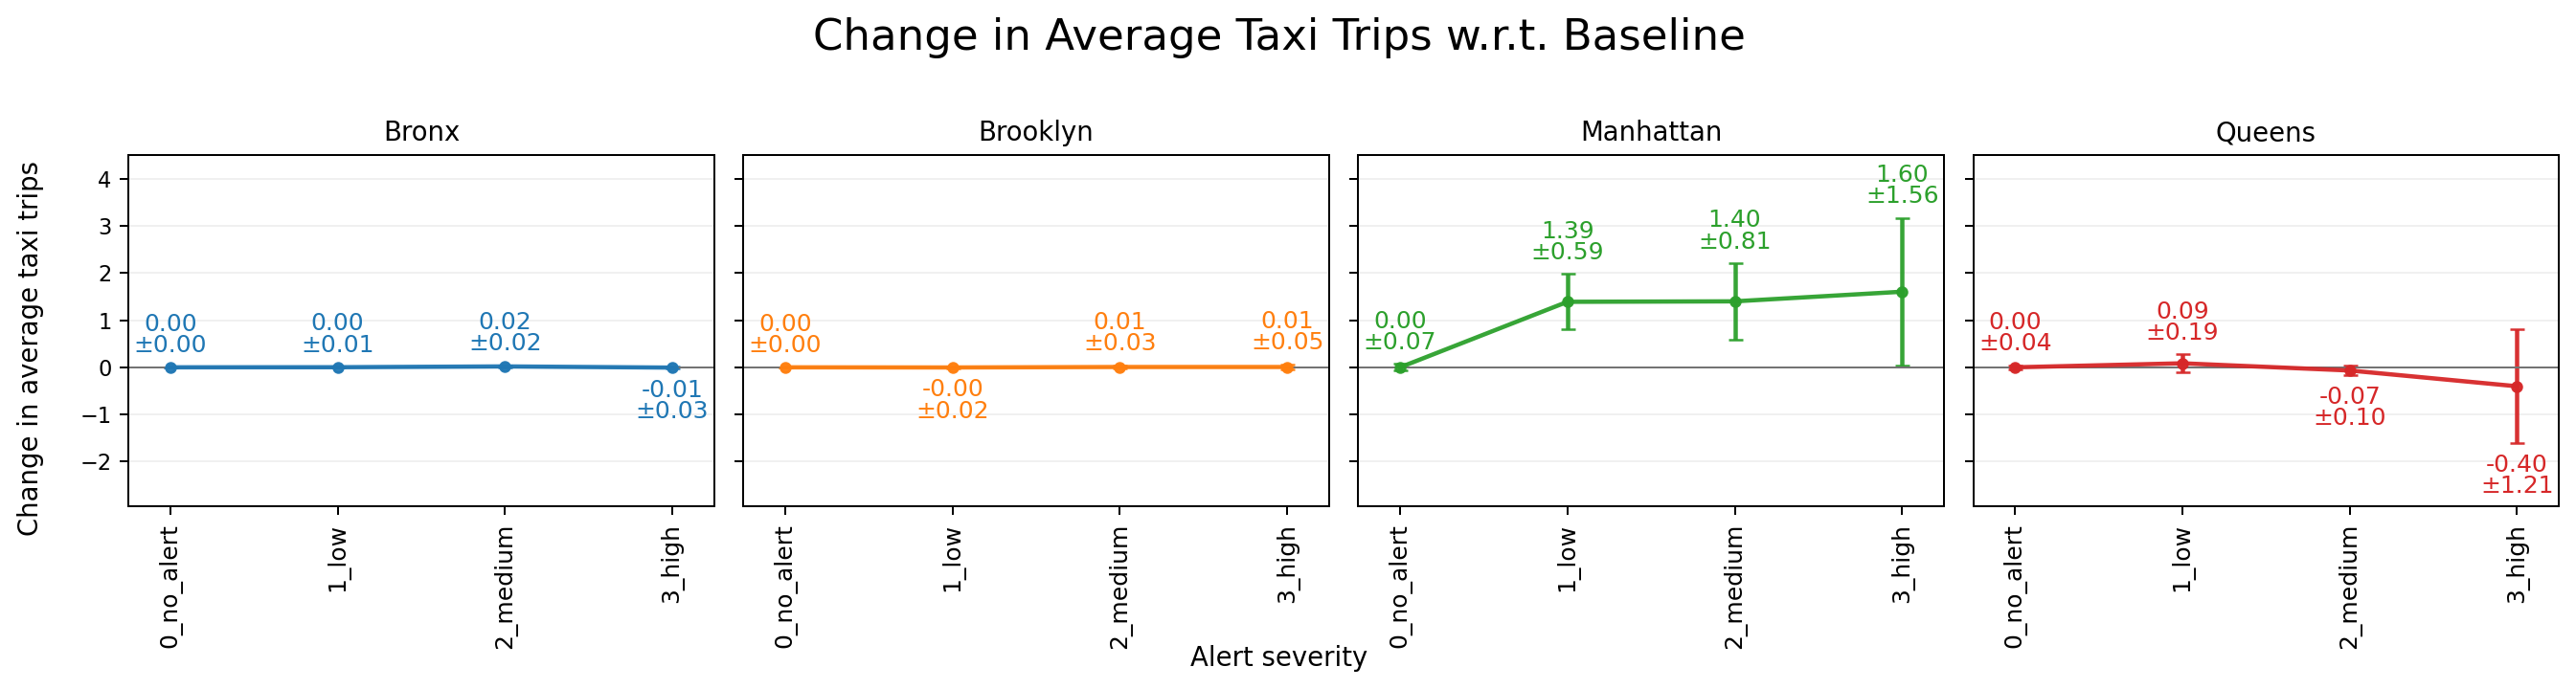

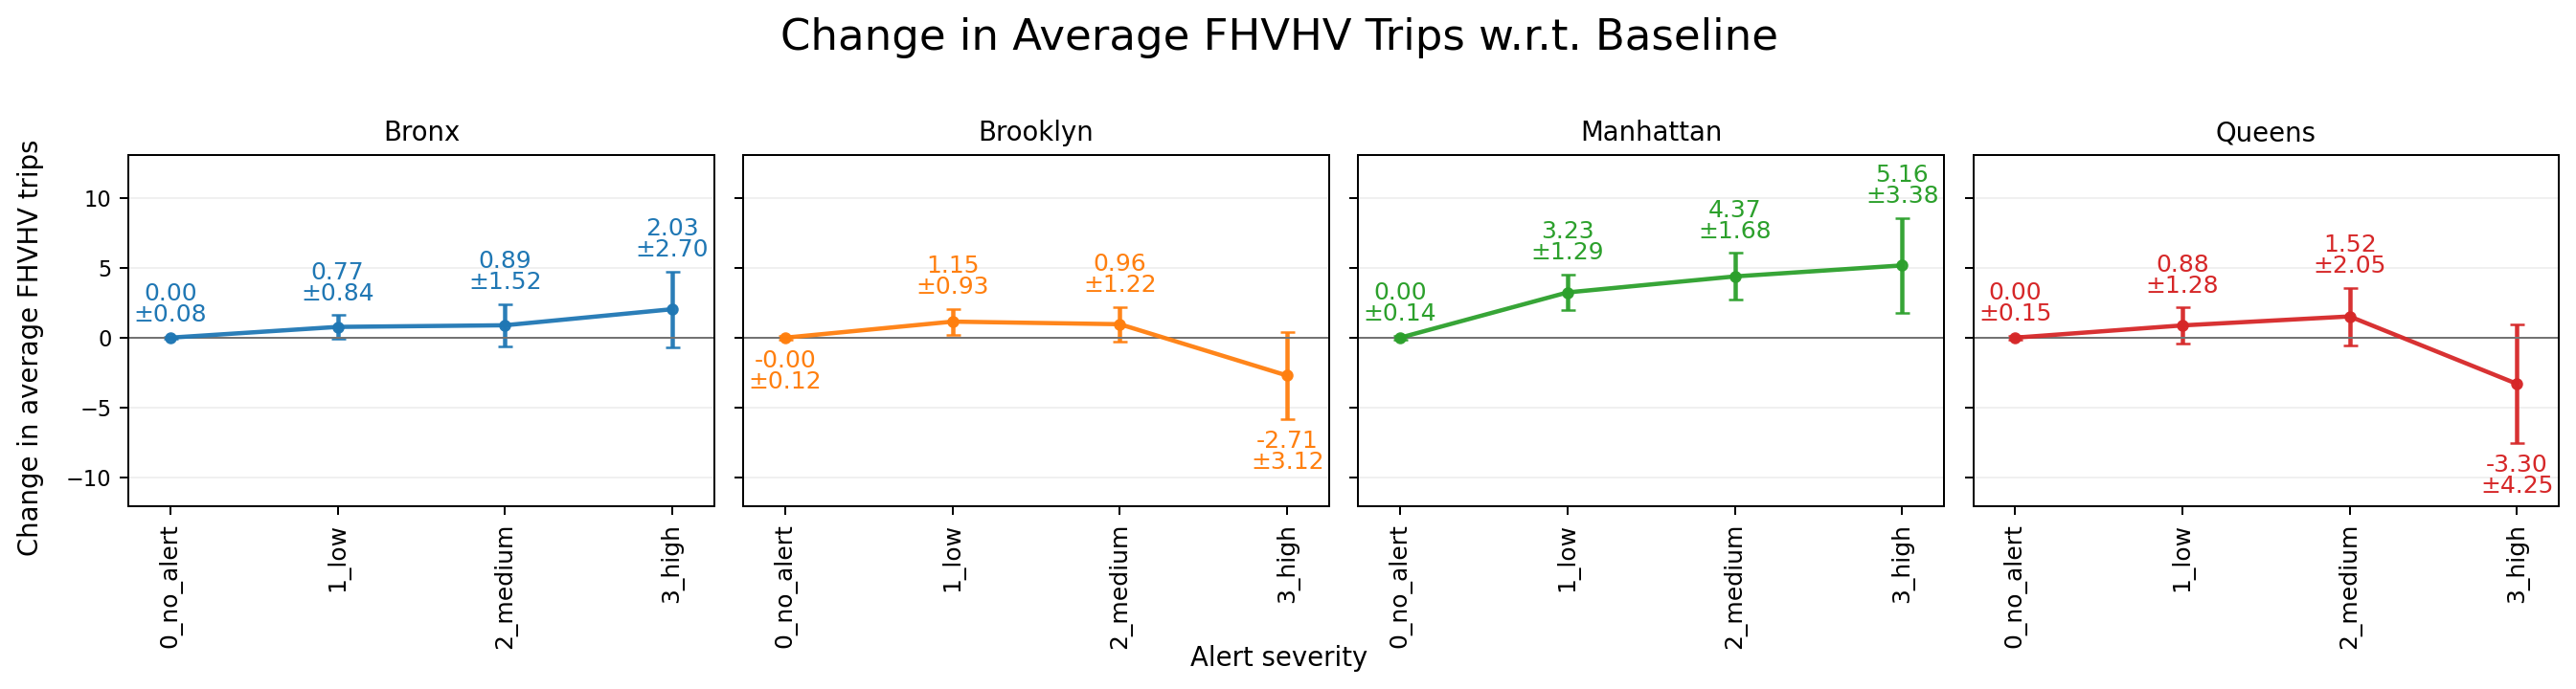

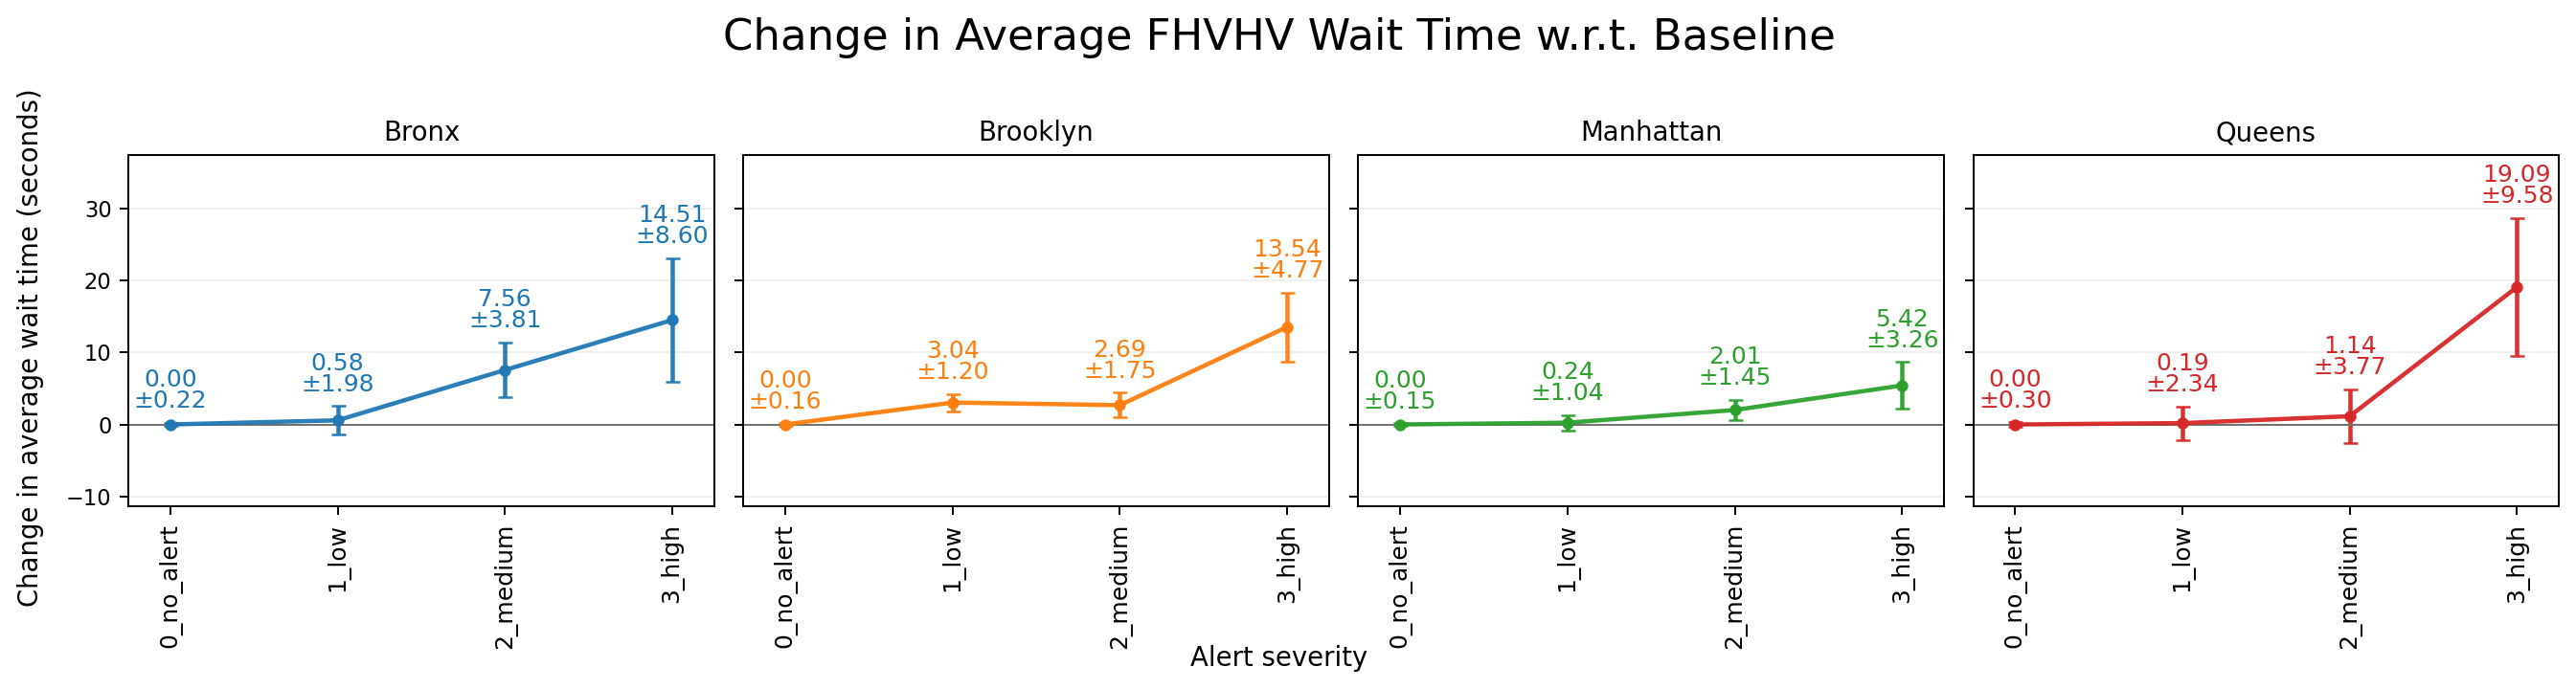

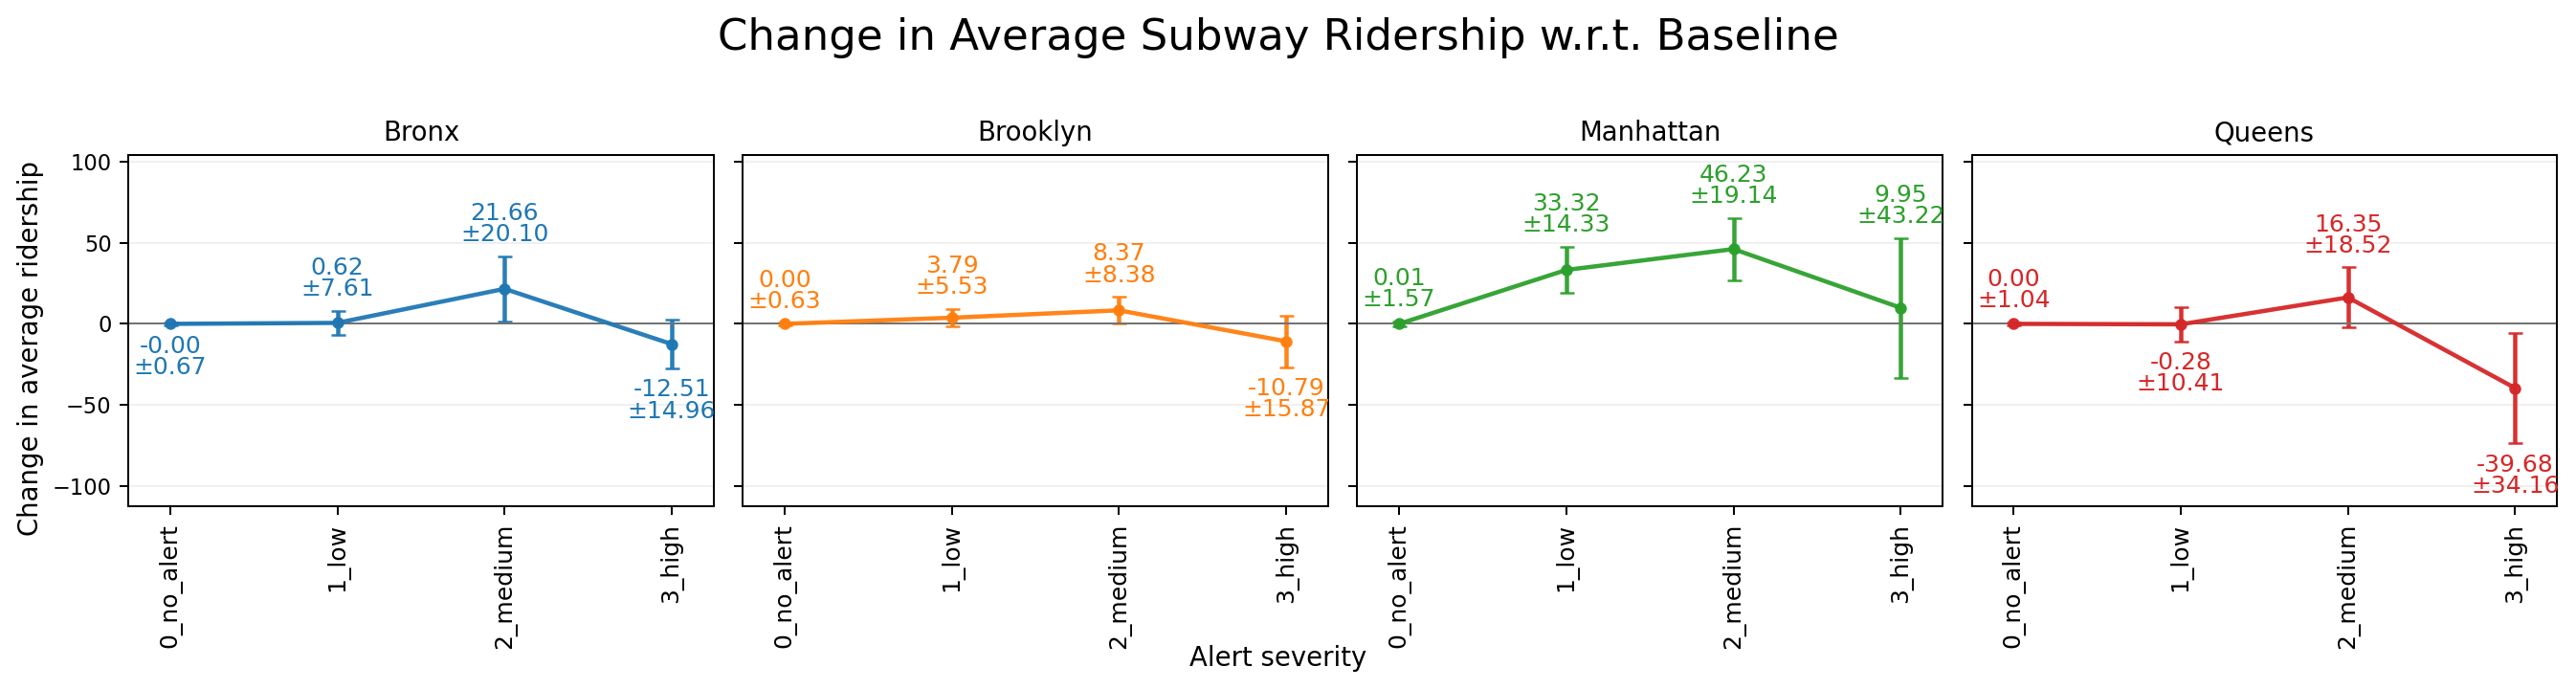

In [27]:
for metric_name in change_metrics:
    plot_borough_ci(metric_name)

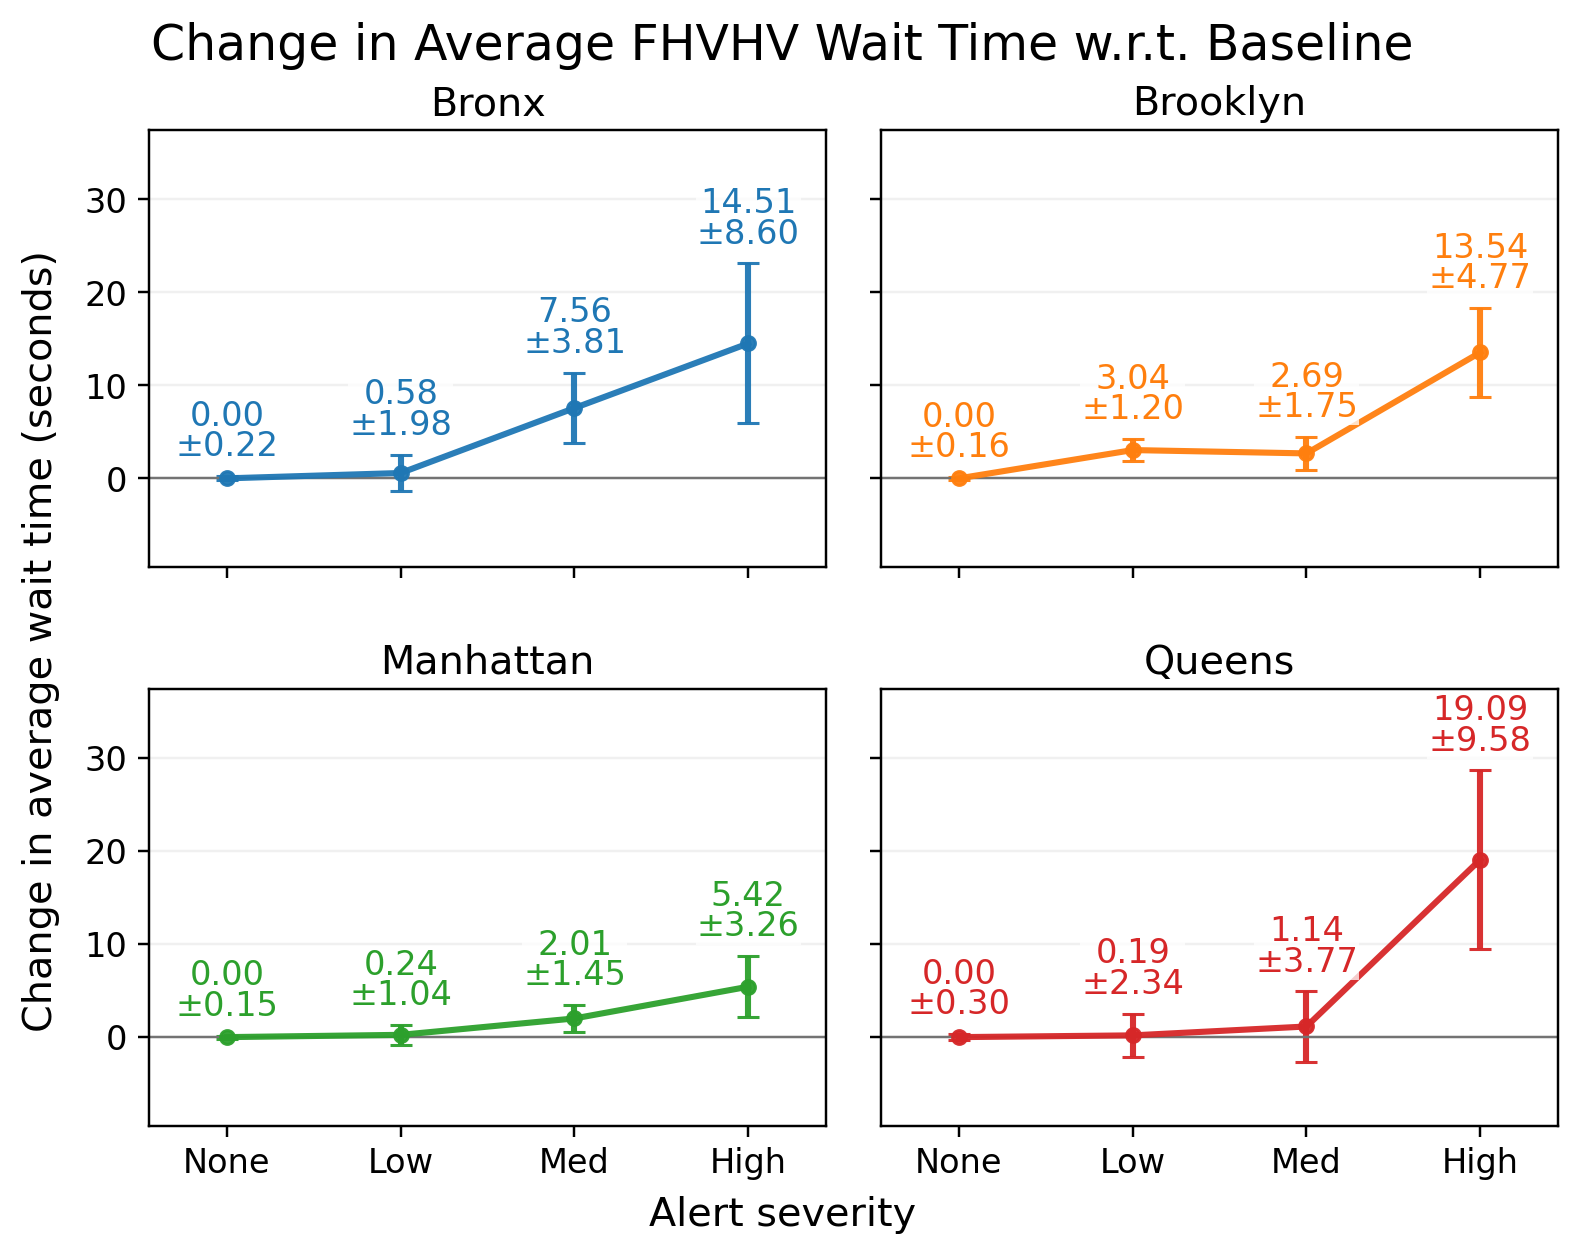

In [28]:
# CI plot function for interpretability 
def plot_borough_ci(metric_name, label_points=True, label_ci=True):
    metric = f"avg_{metric_name}_change"
    ci_metric = f"ci95_{metric_name}_change"
    spec = change_metrics[metric_name]

    x_labels = ["None", "Low", "Med", "High"]
    x = np.arange(len(x_labels))

    fig, axes = plt.subplots(
        2, 2,
        figsize=(7.2, 5.8),
        dpi=220,
        sharex=True,
        sharey=True
    )
    axes = axes.flatten()

    y_all = summary_pd[metric].to_numpy()
    ci_all = summary_pd[ci_metric].to_numpy()

    y_low = (y_all - ci_all).min()
    y_high = (y_all + ci_all).max()
    y_range = y_high - y_low if y_high != y_low else 1

    text_offset = 0.045 * y_range
    y_min = y_low - 0.22 * y_range
    y_max = y_high + 0.28 * y_range

    for ax, borough in zip(axes, borough_order[:4]):
        sub = summary_pd[summary_pd["borough"] == borough].sort_values("alert_level")

        y = sub[metric].to_numpy()
        yerr = sub[ci_metric].to_numpy()
        color = borough_palette[borough]

        ax.errorbar(
            x=x,
            y=y,
            yerr=yerr,
            marker="o",
            markersize=4.5,
            linewidth=2,
            capsize=3.5,
            color=color,
            ecolor=color,
            alpha=0.95
        )

        if label_points:
            for xi, yi, ei in zip(x, y, yerr):
                label = f"{yi:.2f}\n±{ei:.2f}" if label_ci else f"{yi:.2f}"

                label_y = yi + ei + text_offset if yi >= 0 else yi - ei - text_offset
                va = "bottom" if yi >= 0 else "top"

                ax.text(
                    xi,
                    label_y,
                    label,
                    ha="center",
                    va=va,
                    fontsize=11,
                    color=color,
                    linespacing=0.9,
                    bbox=dict(
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.75,
                        pad=0.4
                    )
                )

        ax.axhline(0, color="0.45", linewidth=0.8)
        ax.set_title(borough, fontsize=13, pad=5)
        ax.set_ylim(y_min, y_max)
        ax.set_xlim(-0.45, len(x_labels) - 0.55)
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, fontsize=11)
        ax.tick_params(axis="y", labelsize=11)
        ax.grid(axis="y", alpha=0.18)

    fig.suptitle(spec["title"], fontsize=16, y=0.985)
    fig.supxlabel("Alert severity", fontsize=13, y=0.035)
    fig.supylabel(spec["ylabel"], fontsize=13, x=0.02)

    plt.subplots_adjust(
        left=0.10,
        right=0.99,
        bottom=0.12,
        top=0.90,
        wspace=0.08,
        hspace=0.28
    )
    plt.show()

plot_borough_ci("wait_time")

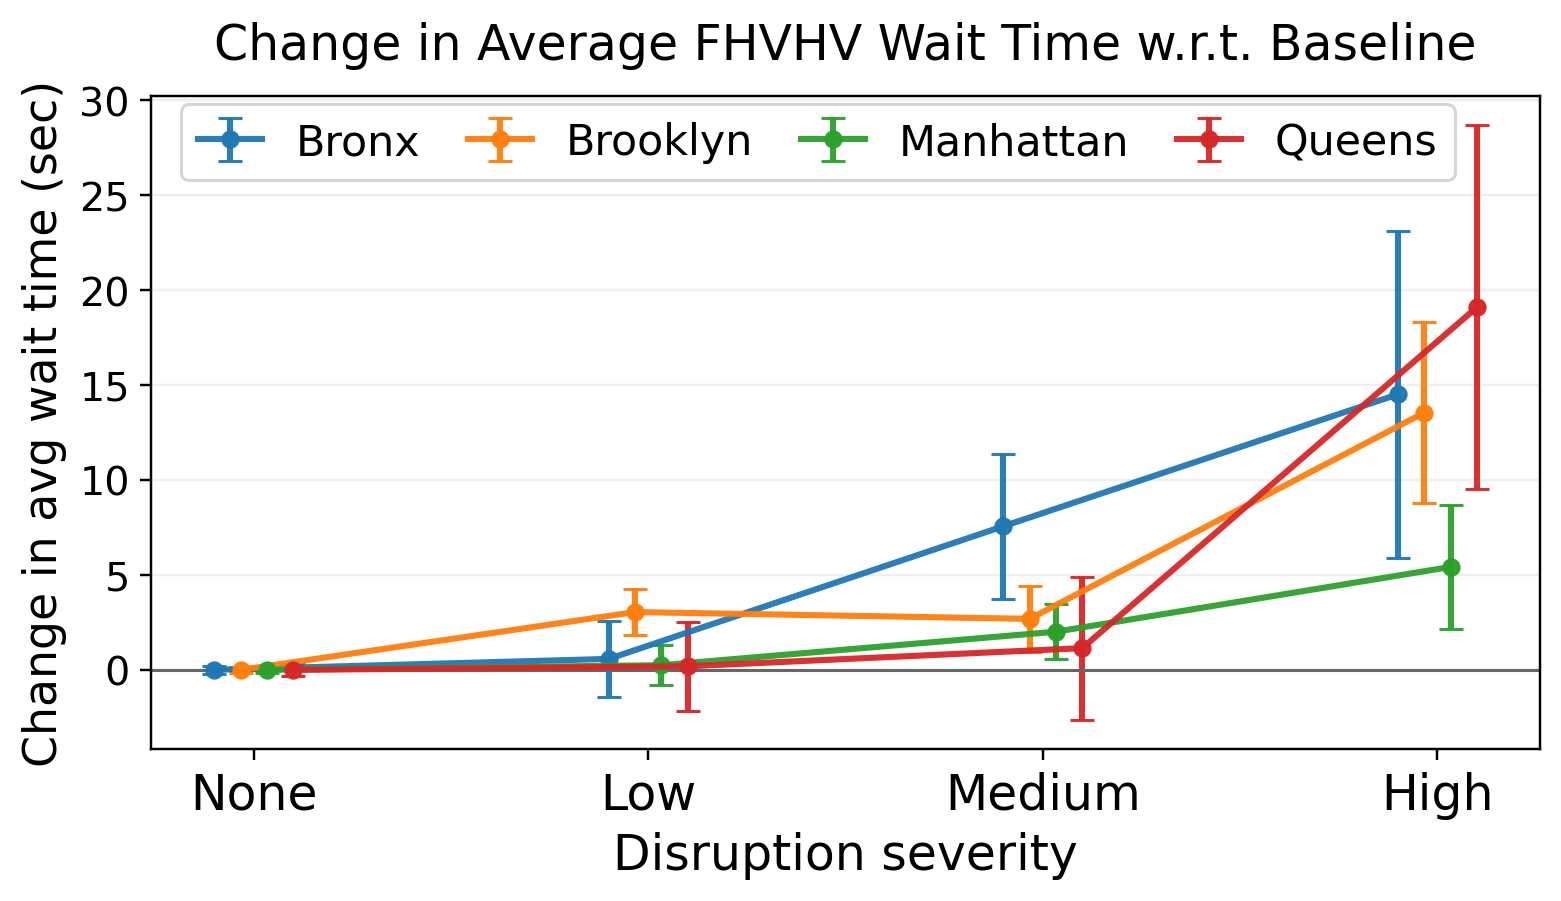

26/08/29 14:01:40 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:131)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.isExecutorAlive$lzycompute$1(BlockManagerMasterEndpoint.scala:707)
	at org.apache.spark.storage.BlockManagerMasterE

In [48]:
def plot_borough_ci_compact(metric_name):
    metric = f"avg_{metric_name}_change"
    ci_metric = f"ci95_{metric_name}_change"
    spec = change_metrics[metric_name]

    x_labels = ["None", "Low", "Medium", "High"]
    x = np.arange(len(x_labels))
    offsets = np.linspace(-0.10, 0.10, len(borough_order[:4]))

    fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=220)

    for borough, offset in zip(borough_order[:4], offsets):
        sub = summary_pd[summary_pd["borough"] == borough].sort_values("alert_level")
        y = sub[metric].to_numpy()
        yerr = sub[ci_metric].to_numpy()
        color = borough_palette[borough]

        ax.errorbar(
            x + offset,
            y,
            yerr=yerr,
            marker="o",
            markersize=5,
            linewidth=2,
            capsize=4,
            color=color,
            ecolor=color,
            label=borough,
            alpha=0.95
        )

    ax.axhline(0, color="0.4", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=16)
    ax.set_xlabel("Disruption severity", fontsize=16)
    ax.set_ylabel(spec["ylabel"], fontsize=15)
    ax.set_title(spec["title"], fontsize=16, pad=12)
    ax.tick_params(axis="y", labelsize=13)
    ax.grid(axis="y", alpha=0.2)

    ax.legend(
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.48, 1.02),
        fontsize=14,
        frameon=True,
        columnspacing=1.1,
        handlelength=1.5
    )

    plt.tight_layout()
    plt.show()

plot_borough_ci_compact("wait_time")

In [30]:
# An extra check for taxi change (to support by-borough analysis)
taxi_sparsity_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 3).alias("avg_taxi_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 3).alias("avg_baseline_taxi_trips"),
        F.round(F.avg("taxi_trip_change"), 3).alias("avg_taxi_trip_change"),
        F.expr("percentile_approx(n_trips_taxi, array(0.5, 0.75, 0.9, 0.99))").alias("taxi_trip_quantiles"),
        F.round(F.avg((F.col("n_trips_taxi") == 0).cast("double")), 3).alias("zero_taxi_trip_prop"),
    )
    .orderBy("borough", "alert_level")
)

taxi_sparsity_summary.show(100, truncate=False)

+---------+-----------+------------+--------------+-----------------------+--------------------+-------------------+-------------------+
|borough  |alert_level|n_zone_hours|avg_taxi_trips|avg_baseline_taxi_trips|avg_taxi_trip_change|taxi_trip_quantiles|zero_taxi_trip_prop|
+---------+-----------+------------+--------------+-----------------------+--------------------+-------------------+-------------------+
|Bronx    |0_no_alert |339983      |0.047         |0.047                  |0.0                 |[0, 0, 0, 1]       |0.96               |
|Bronx    |1_low      |4148        |0.071         |0.069                  |0.002               |[0, 0, 0, 1]       |0.945              |
|Bronx    |2_medium   |1998        |0.111         |0.091                  |0.019               |[0, 0, 0, 2]       |0.923              |
|Bronx    |3_high     |559         |0.086         |0.091                  |-0.006              |[0, 0, 0, 1]       |0.921              |
|Brooklyn |0_no_alert |576258      |0.396

### Interaction analysis: findings and interpretation

Visually, there is clear interaction between how the effect of alert severity on `n_trips_taxi`, `n_trips_fhvhv`, and `avg_wait_time_fhvhv` changes, depending on the borough. More specifically:
- For `n_trips_taxi`: compared to the baseline level, Manhattan sees a much larger increase compared to all other boroughs 
- For `n_trips_fhvhv`: Manhattan with the steepest increase, Bronx a mild increase, and decreases in Brooklyn and Queens 
- For `avg_wait_time_fhvhv`: Queens with the steepest increase, followed by Bronx then Brooklyn; Manhattan has a noticeably milder increase 
- For `ridership`: increase is steepest in Manhattan from alert severity 0 to 1; otherwise the gradient changes are similar betwen boroughs, though at different values 
- Combining observations from `n_trips_fhvhv` and `avg_wait_time_fhvhv`, we might hypothesise that there is a preference to dispatch services to Manhattan, as the demand (services matched) increases the most rapidly and the wait time increases least rapidly, out of the 4 boroughs in this analysis. 

## Correlation analysis 
Based on our distribution analysis above, we will use the log transformation for `n_trips_taxi`, `n_trips_fhvhv`, `avg_wait_time_fhvhv`, `ridership`, `n_alerts`.

### Global correlation analysis

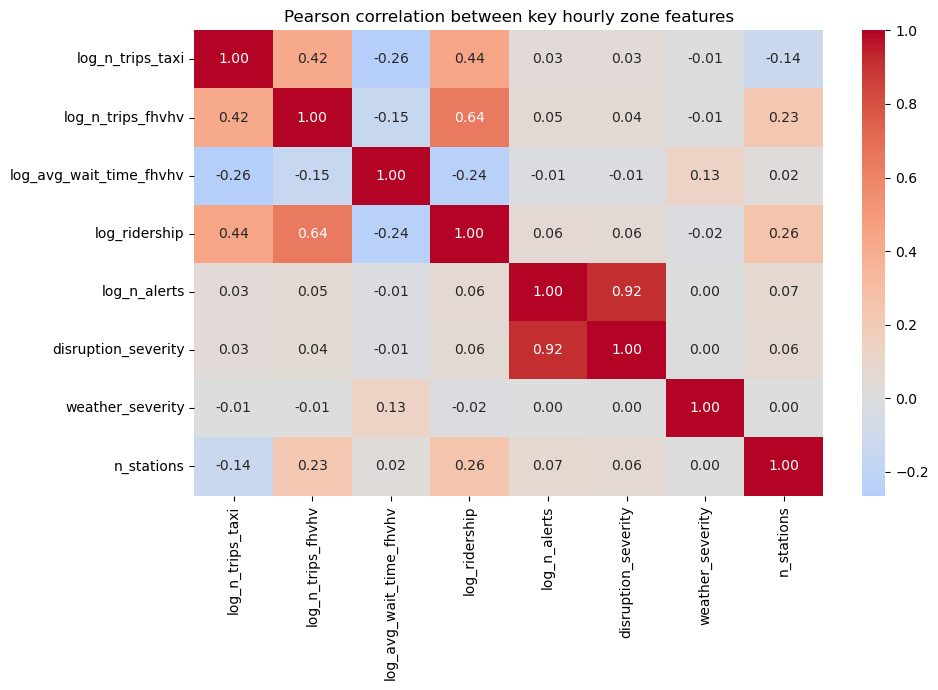

In [31]:
# Build initial correlation matrix for all features in `sdf_tlc_hourly`
corr_df = (
    sdf_tlc_hourly
    .withColumn("log_n_trips_taxi", F.log1p("n_trips_taxi"))
    .withColumn("log_n_trips_fhvhv", F.log1p("n_trips_fhvhv"))
    .withColumn("log_gross_fare_taxi", F.log1p("gross_fare_taxi"))
    .withColumn("log_gross_fare_fhvhv", F.log1p("gross_fare_fhvhv"))
    .withColumn("log_avg_wait_time_fhvhv", F.log1p("avg_wait_time_fhvhv"))
    .withColumn("log_ridership", F.log1p("ridership"))
    .withColumn("log_n_alerts", F.log1p("n_alerts"))
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
    .withColumn("has_severe_disruption", (F.col("disruption_severity") >= 3).cast("int"))
)
corr_cols = [
    "log_n_trips_taxi",
    "log_n_trips_fhvhv",
    "log_avg_wait_time_fhvhv",
    "log_ridership",
    "log_n_alerts",
    "disruption_severity",
    "weather_severity",
    "n_stations",
]

corr_pd = corr_df.select(corr_cols).toPandas()
corr_matrix = corr_pd.corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Pearson correlation between key hourly zone features")
plt.tight_layout()
plt.show()

### By-borough correlation analysis 
Based on our interaction analysis, we might want to examine the correlation between attributes for each borough individually. 

In [32]:
# Build correlation dataframe for each borough 
borough_corrs = {}
for borough in ["Bronx", "Brooklyn", "Manhattan", "Queens"]:
    corr_pd = (
        corr_df
        .filter(F.col("borough") == borough)
        .select(corr_cols)
        .dropna()
        .toPandas()
    )

    borough_corrs[borough] = corr_pd.corr(method="pearson")

In [33]:
# Display correlation stats of most interest in table format
key_corr_rows = []
for borough, corr in borough_corrs.items():
    key_corr_rows.append({
        "borough": borough,
        "ridership_vs_fhvhv_trips": corr.loc["log_ridership", "log_n_trips_fhvhv"],
        "ridership_vs_taxi_trips": corr.loc["log_ridership", "log_n_trips_taxi"],
        "severity_vs_fhvhv_trips": corr.loc["disruption_severity", "log_n_trips_fhvhv"],
        "severity_vs_taxi_trips": corr.loc["disruption_severity", "log_n_trips_taxi"],
        "severity_vs_wait_time": corr.loc["disruption_severity", "log_avg_wait_time_fhvhv"],
        "weather_vs_wait_time": corr.loc["weather_severity", "log_avg_wait_time_fhvhv"],
    })

borough_key_corr_pd = pd.DataFrame(key_corr_rows)
borough_key_corr_pd

,borough,ridership_vs_fhvhv_trips,ridership_vs_taxi_trips,severity_vs_fhvhv_trips,severity_vs_taxi_trips,severity_vs_wait_time,weather_vs_wait_time
0,Bronx,0.562198,0.121589,0.032904,0.018537,-0.000672,0.157610
1,Brooklyn,0.640609,0.195376,0.037015,0.028246,0.009382,0.138550
2,Manhattan,0.692793,0.641785,0.053464,0.042052,-0.010414,0.143858
3,Queens,0.597120,0.186277,0.025742,0.020540,-0.025923,0.113117


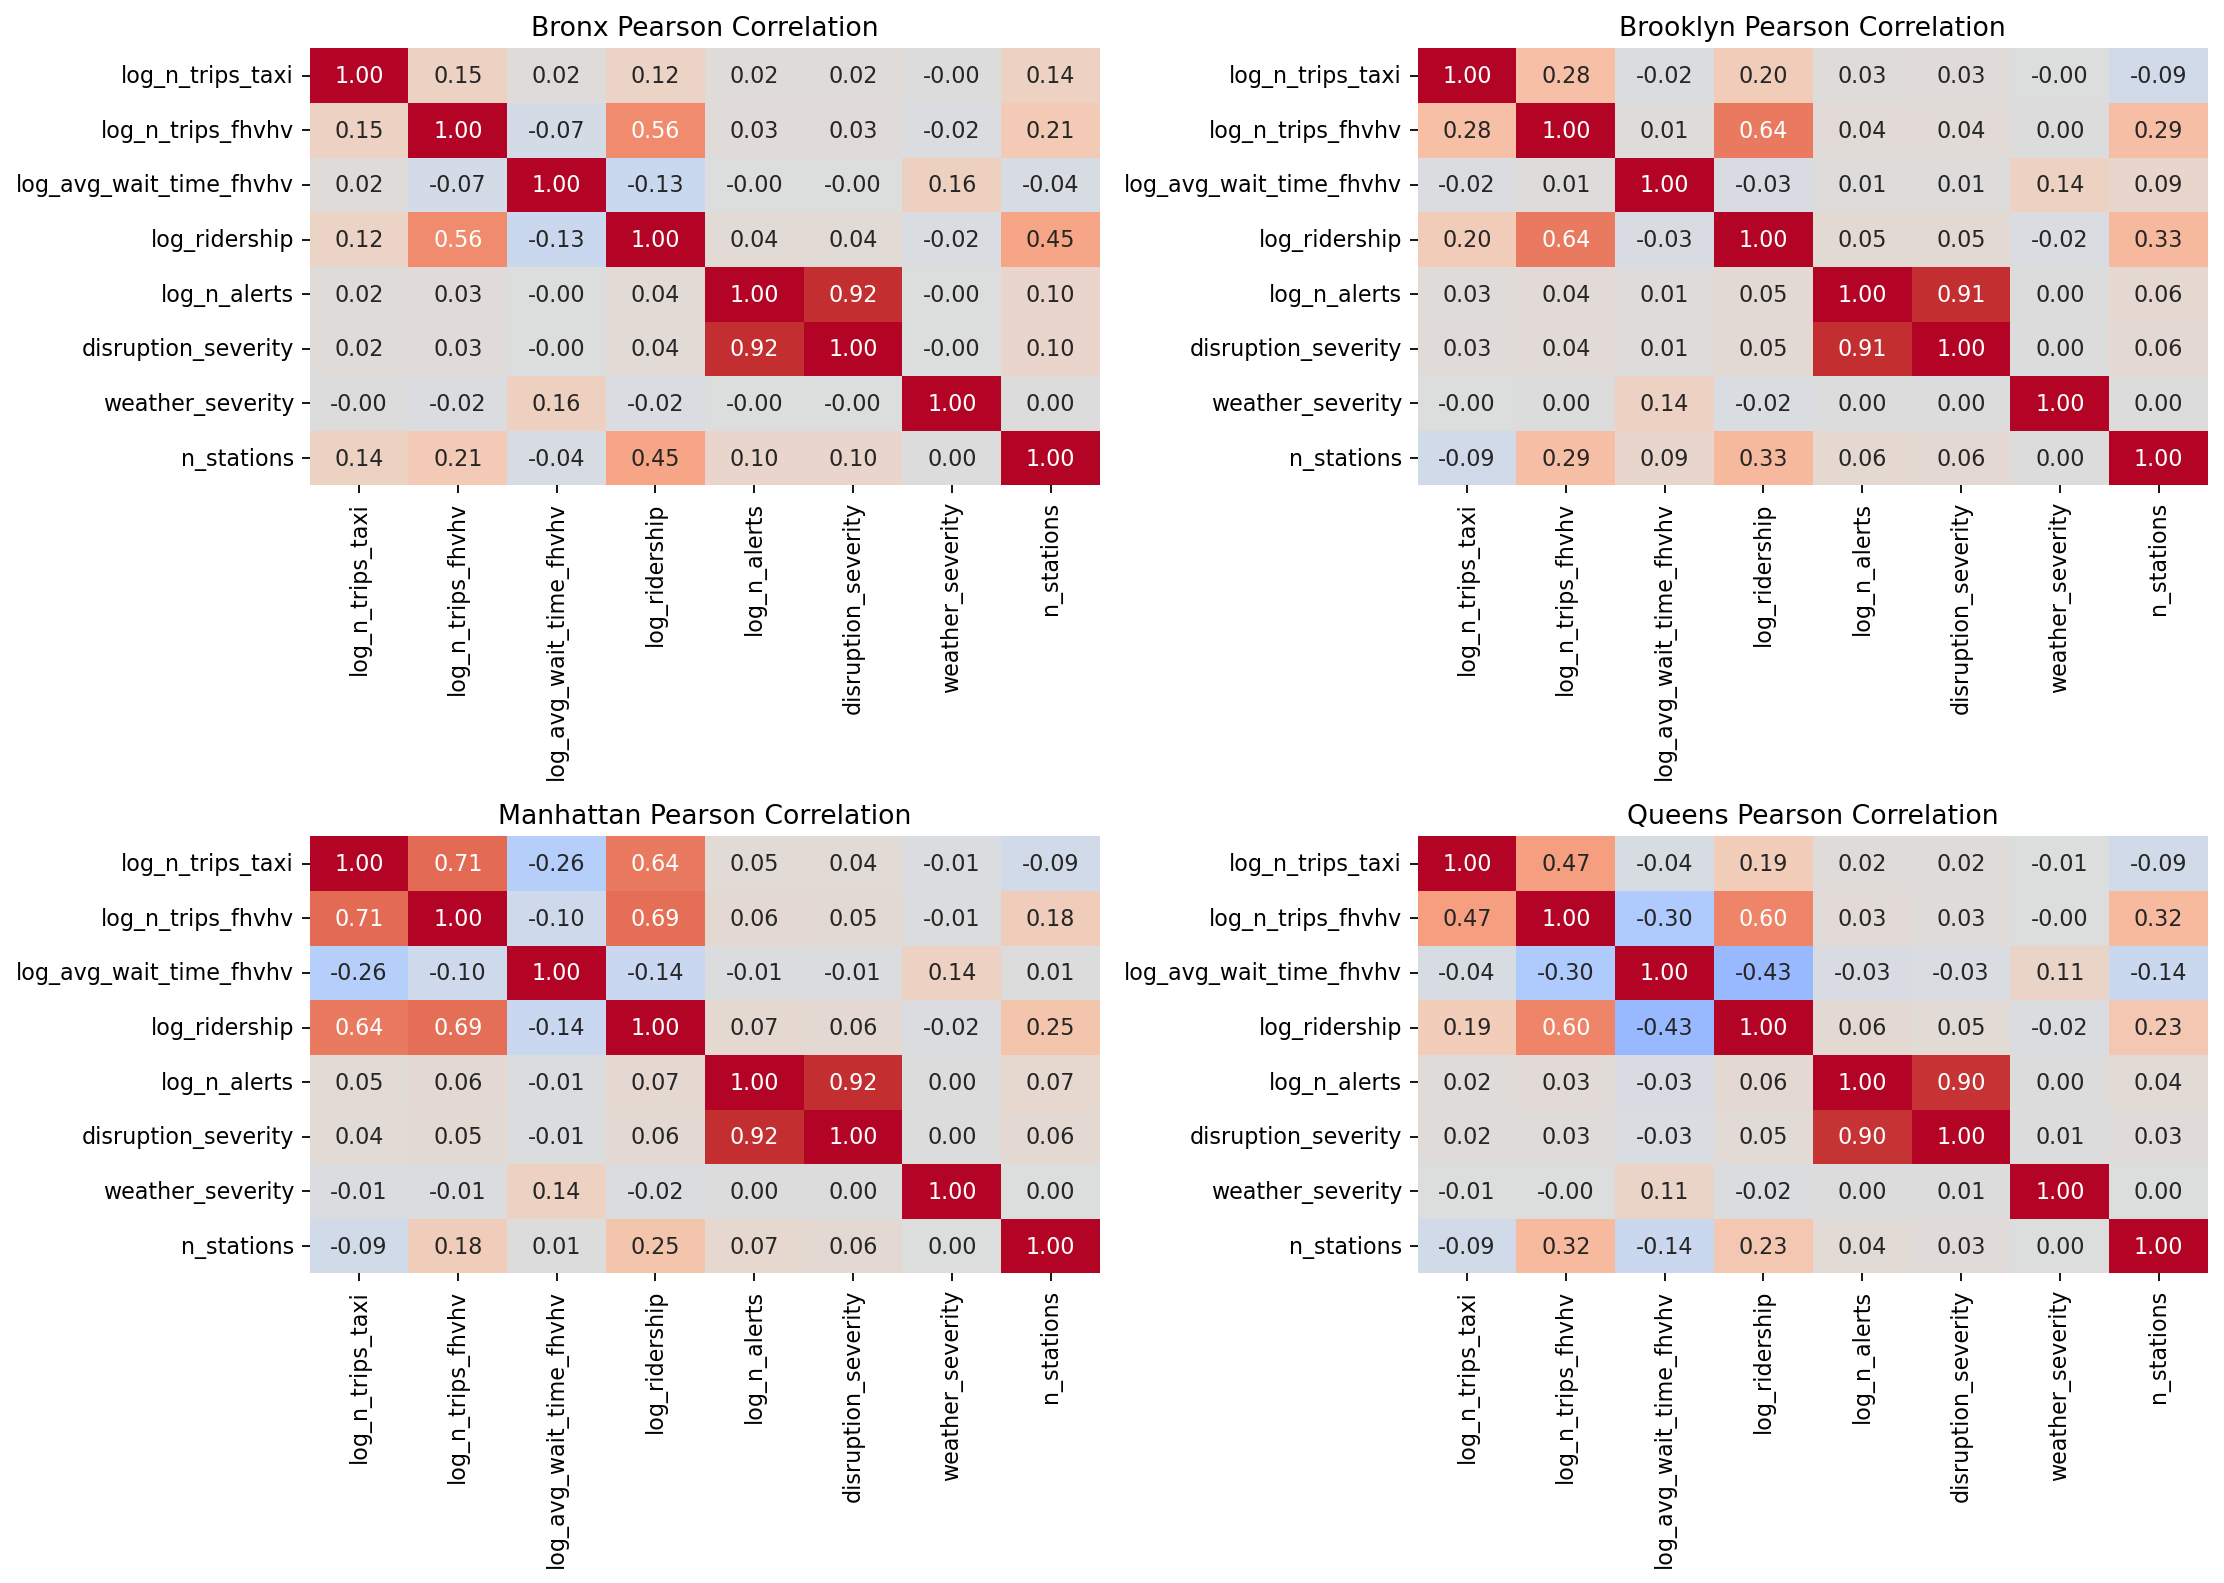

In [34]:
# Print correlation matrix per borough 
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=160)

for ax, borough in zip(axes.flatten(), ["Bronx", "Brooklyn", "Manhattan", "Queens"]):
    sns.heatmap(
        borough_corrs[borough],
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f",
        ax=ax,
        cbar=False
    )
    ax.set_title(f"{borough} Pearson Correlation")

plt.tight_layout()
plt.show()

## Checkpoints 
... write here after conducting correlation analysis